# Securing Mission-Critical UAV Metadata Through AES Encryption, SSA-Based Shuffling, and Reversible Data Hiding

Google Colab implementation of the Review-1 architecture (Batch 08, CBIT):

**Encoder:** UAV capture → metadata extractor (EXIF / XMP / SRT / dataset telemetry) → cover preprocessor (lossless pixels, SHA-256) → filter + serializer (field whitelist → CBOR, adds H(cover)) → AES-256-GCM → SSA shuffler (keyed bit permutation) → RDH embedder (PEE + histogram shifting, keyed pixel order, texture-adaptive stealth selection) → secure PNG.

**Decoder:** RDH extractor (bits out + image restored) → inverse shuffle → AES-GCM decrypt / verify tag → binding check H(restored) = H(cover) → original image + metadata JSON + verdict.

Keys: one HKDF-SHA256 key manager derives K_enc, K_shuf and K_loc.

Base paper (acknowledged throughout): Alkodre et al., "A Shuffling-Steganography Algorithm to Protect Data of Drone Applications", CMC 81(2), 2024, doi:10.32604/cmc.2024.053706.

**Integrity rules followed in this notebook**
- Every number printed or saved is computed by the code in this notebook; nothing is typed in by hand.
- Synthetic metadata is generated only for fields a dataset does not provide; each synthetic field is listed in the record under `syn` and in the result tables.
- Exact recovery is claimed only for the unmodified (lossless) channel. Under JPEG, noise, resizing etc. the scheme is tested for *rejection*, not recovery.
- The SSA shuffle is not claimed to add cryptographic security; confidentiality and integrity come from AES-256-GCM. The shuffle's effect is measured.

Run the cells top to bottom in a fresh Colab runtime (Runtime → Run all).

## 1. Environment setup
Installs the few packages Colab does not ship with. `exiftool` (via apt) is used for EXIF/XMP when available; Pillow is the fallback.

In [ ]:
import sys, subprocess, importlib

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

for mod, pkg in [("cbor2", "cbor2"), ("exiftool", "pyexiftool"), ("cryptography", "cryptography"),
                 ("skimage", "scikit-image"), ("cv2", "opencv-python-headless")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        _pip(pkg)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run(["apt-get", "-qq", "install", "-y", "libimage-exiftool-perl"], check=False,
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

In [ ]:
import os, io, json, time, math, glob, re, zlib, struct, shutil, hashlib, random, tracemalloc, warnings
from dataclasses import dataclass, field
from datetime import datetime, timezone

import numpy as np
import cv2
import cbor2
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ExifTags
from scipy import stats
from skimage.metrics import structural_similarity, peak_signal_noise_ratio
from cryptography.hazmat.primitives import hashes
from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from cryptography.hazmat.primitives.ciphers import Cipher, algorithms, modes
from cryptography.exceptions import InvalidTag

try:
    import exiftool  # pyexiftool
    HAVE_EXIFTOOL = shutil.which("exiftool") is not None
except Exception:
    HAVE_EXIFTOOL = False

# Reproducibility: seeds control dataset sampling, synthetic fields and attack locations.
# Cryptographic randomness (keys, salts, nonces) always comes from os.urandom and is NOT seeded.
GLOBAL_SEED = 2026
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

RUN_DIR = os.path.abspath("uavmeta_run")
DATA_DIR = os.path.abspath("uavmeta_data")
for d in [RUN_DIR, DATA_DIR, f"{RUN_DIR}/figures", f"{RUN_DIR}/tables", f"{RUN_DIR}/marked"]:
    os.makedirs(d, exist_ok=True)

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| opencv", cv2.__version__,
      "| exiftool available:", HAVE_EXIFTOOL, "| Colab:", IN_COLAB)

Python 3.13.18 | numpy 2.4.6 | opencv 5.0.0 | exiftool available: True | Colab: True


## 2. Dataset acquisition (Kaggle API + Colab Secrets)

This notebook uses the three Kaggle datasets specified for this study plus **ODM (OpenDroneMap) photos** (Section 2b), the only source whose images carry real, camera-written EXIF/XMP flight metadata:

- **AU-AIR** — `furqanqureshi/au-air-dataset`; primary source for UAV images and available per-image flight telemetry annotations.
- **VisDrone** — `kushagrapandya/visdrone-dataset`; UAV images used as cover images. Its object-detection annotations are not flight telemetry.
- **UAVid** — `dasmehdixtr/uavid-v1`; UAV images used as cover images. Its semantic-segmentation labels are not flight telemetry.

Add your Kaggle credentials in Colab → Secrets and enable notebook access to them. Either option works:

- `KAGGLE_USERNAME` + `KAGGLE_KEY` (the classic pair from `kaggle.json`), or
- `KAGGLE_API_TOKEN` (a single newer-style token).

Do not paste credentials into a code cell.

**Storage clarification:** Kaggle API access transfers the dataset files into the Colab runtime/cache so Python can read them. This avoids storing the datasets on your personal computer or permanently in Google Drive; it is not remote, zero-download streaming. Large datasets require enough Colab disk space.

The notebook fetches the exact dataset handles above. It does not silently substitute another Kaggle mirror or scikit-image sample photographs. If any required dataset cannot be fetched or contains no usable images, execution stops with an actionable error rather than changing the study's dataset composition. Folder discovery is recursive to support nested image and split folders.


In [ ]:
import os, glob, json, subprocess, sys

# Colab secrets: KAGGLE_USERNAME + KAGGLE_KEY (classic kaggle.json pair) OR KAGGLE_API_TOKEN (new single token).
# Exact Kaggle dataset handles supplied for this study.
KAGGLE_DATASET_HANDLES = {
    "AU-AIR": "furqanqureshi/au-air-dataset",
    "VisDrone": "kushagrapandya/visdrone-dataset",
    "UAVid": "dasmehdixtr/uavid-v1",
}

DATA_DIR = os.path.abspath("uavmeta_data")
os.makedirs(DATA_DIR, exist_ok=True)

def load_kaggle_credentials():
    """Copies Kaggle credentials from Colab Secrets into environment variables.
    Supports KAGGLE_USERNAME + KAGGLE_KEY or KAGGLE_API_TOKEN. Values are never printed."""
    names = ["KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN"]
    if "google.colab" in sys.modules:
        try:
            from google.colab import userdata
            for n in names:
                if not os.environ.get(n):
                    try:
                        v = userdata.get(n)
                        if v:
                            os.environ[n] = v
                    except Exception:
                        pass
        except Exception as e:
            print("Could not access Colab Secrets:", type(e).__name__)
    if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
        os.environ.pop("KAGGLE_API_TOKEN", None)   # use one auth method only
        return "username+key"
    if os.environ.get("KAGGLE_API_TOKEN"):
        return "token"
    return None

KAGGLE_AUTH = load_kaggle_credentials()
KAGGLEHUB_AVAILABLE = False
if KAGGLE_AUTH:
    try:
        import importlib.util
        if importlib.util.find_spec("kagglehub") is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
        # No explicit login(): kagglehub reads KAGGLE_USERNAME/KAGGLE_KEY (or KAGGLE_API_TOKEN) from the
        # environment automatically, and login() signatures differ across kagglehub versions.
        KAGGLEHUB_AVAILABLE = True
        print(f"Kaggle authentication: {KAGGLE_AUTH} (values hidden)")
    except Exception as e:
        print("Kaggle authentication/setup failed:", type(e).__name__, str(e)[:250])
else:
    print("No Kaggle credentials found. Add KAGGLE_USERNAME + KAGGLE_KEY (or KAGGLE_API_TOKEN) "
          "under Colab Secrets and enable notebook access.")

# KaggleHub downloads/extracts files into Colab's local cache; no copy to Drive is made.
def fetch_kaggle_dataset(label, handle):
    if not KAGGLEHUB_AVAILABLE:
        raise RuntimeError(
            "Kaggle authentication is unavailable. Add KAGGLE_USERNAME + KAGGLE_KEY (or KAGGLE_API_TOKEN) "
            "in Colab Secrets, enable notebook access, then rerun this cell."
        )
    try:
        path = kagglehub.dataset_download(handle)
        if os.path.isdir(path):
            print(f"{label}: ready at {path}")
            return path
        raise RuntimeError(f"KaggleHub returned no directory for {handle}: {path}")
    except Exception as e:
        raise RuntimeError(
            f"Could not fetch required dataset {label} ({handle}). "
            f"Check the Kaggle handle, dataset access/acceptance requirements, and credentials. "
            f"Underlying error: {type(e).__name__}: {str(e)[:300]}"
        ) from e

def list_images(folder, exts=(".jpg", ".jpeg", ".png", ".tif", ".tiff", ".pgm", ".bmp")):
    if not folder or not os.path.isdir(folder):
        return []
    out = []
    for root, _, files in os.walk(folder):
        out += [os.path.join(root, f) for f in files if f.lower().endswith(exts)]
    return sorted(out)

# Fetch exactly the three requested datasets.
AUAIR_DIR = fetch_kaggle_dataset("AU-AIR", KAGGLE_DATASET_HANDLES["AU-AIR"])
VISDRONE_DIR = fetch_kaggle_dataset("VisDrone", KAGGLE_DATASET_HANDLES["VisDrone"])
UAVID_DIR = fetch_kaggle_dataset("UAVid", KAGGLE_DATASET_HANDLES["UAVid"])

AUAIR_IMAGES = list_images(AUAIR_DIR)
VISDRONE_IMAGES = list_images(VISDRONE_DIR)
UAVID_IMAGES = list_images(UAVID_DIR)

DATASET_STATUS = {
    "AU-AIR": len(AUAIR_IMAGES),
    "VisDrone": len(VISDRONE_IMAGES),
    "UAVid": len(UAVID_IMAGES),
}
print("\nDataset image counts:")
print(json.dumps(DATASET_STATUS, indent=2))

_empty = [name for name, count in DATASET_STATUS.items() if count == 0]
if _empty:
    raise RuntimeError(
        "Required dataset(s) contain no discoverable image files: " + ", ".join(_empty) +
        ". Inspect the Kaggle archive folder structure and image extensions before proceeding."
    )

# Display likely AU-AIR annotation files for a quick dataset-structure check.
_json_files = glob.glob(os.path.join(AUAIR_DIR, "**", "*.json"), recursive=True)
print("AU-AIR JSON files found:", len(_json_files))
print("AU-AIR JSON examples:", [os.path.relpath(x, AUAIR_DIR) for x in _json_files[:8]])


Kaggle authentication: username+key (values hidden)


100%|██████████| 2.18G/2.18G [00:44<00:00, 53.0MB/s]

Extracting files...


AU-AIR: ready at /root/.cache/kagglehub/datasets/furqanqureshi/au-air-dataset/versions/1


100%|██████████| 2.10G/2.10G [00:25<00:00, 87.1MB/s]

Extracting files...


VisDrone: ready at /root/.cache/kagglehub/datasets/kushagrapandya/visdrone-dataset/versions/1


100%|██████████| 10.9G/10.9G [02:01<00:00, 96.7MB/s]

Extracting files...


UAVid: ready at /root/.cache/kagglehub/datasets/dasmehdixtr/uavid-v1/versions/3

Dataset image counts:
{
  "AU-AIR": 32823,
  "VisDrone": 10209,
  "UAVid": 1490
}
AU-AIR JSON files found: 1
AU-AIR JSON examples: ['AU-AIR dataset/annotations.json']


### 2b. ODM (OpenDroneMap) photos — real drone metadata

AU-AIR ships flight telemetry in a JSON file; VisDrone and UAVid ship **no** flight metadata, so their records are mostly synthetic. ODM project photos are raw drone captures with the GPS position, altitude, capture time and camera parameters written into EXIF/XMP by the aircraft itself (DJI photos also carry roll/pitch/yaw in XMP). They are therefore the most realistic test of the metadata extractor and of the real-metadata payload.

Set `ODM_SOURCE` to a Kaggle handle, a Google Drive folder or an uploaded `.zip`. Left empty, the cell auto-discovers a folder/archive whose name contains `odm` under `/content`, `/content/drive/MyDrive` or the KaggleHub cache. Only photos inside ODM's `images/` folders are used (orthophotos and preview images are skipped).

In [ ]:
#@title ODM (OpenDroneMap) photos: real drone images with real EXIF/XMP metadata
# Where your ODM data is. Leave empty to auto-discover any folder or .zip whose name contains "odm" in
# /content (uploaded files), /content/drive/MyDrive (Google Drive) or the KaggleHub cache. Accepted values:
#   * a Kaggle dataset handle, e.g. "yourname/odm-data"
#   * a folder, e.g. "/content/drive/MyDrive/odm_data_aukerman"
#   * a .zip/.tar archive, e.g. "/content/odm_data_aukerman-master.zip"
ODM_SOURCE = "/content/sample_data/images"  #@param {type:"string"}
REQUIRE_ODM = False  #@param {type:"boolean"}
ODM_SOURCE = os.environ.get("ODM_SOURCE", ODM_SOURCE).strip()

import re, hashlib, shutil

def _maybe_mount_drive(path):
    if IN_COLAB and path.startswith("/content/drive") and not os.path.isdir("/content/drive/MyDrive"):
        from google.colab import drive
        drive.mount("/content/drive")

def _unpack(archive):
    dest = os.path.join(DATA_DIR, "odm_" + hashlib.sha1(os.path.abspath(archive).encode()).hexdigest()[:8])
    if not os.path.isdir(dest) or not os.listdir(dest):
        print("Extracting", archive, "->", dest)
        shutil.unpack_archive(archive, dest)
    return dest

_ARCHIVE_EXT = (".zip", ".tar", ".tar.gz", ".tgz")

def _discover_odm(max_depth=4):
    roots = ["/content", "/content/drive/MyDrive", os.path.expanduser("~/.cache/kagglehub/datasets"),
             "/kaggle/input", os.getcwd()]
    found, seen = [], set()
    for root in roots:
        if not os.path.isdir(root):
            continue
        base = root.rstrip("/").count("/")
        for dirpath, dirnames, filenames in os.walk(root):
            if dirpath.rstrip("/").count("/") - base >= max_depth or "uavmeta_run" in dirpath:
                dirnames[:] = []
                continue
            for d in dirnames:
                full = os.path.realpath(os.path.join(dirpath, d))
                if "odm" in d.lower() and full not in seen:
                    seen.add(full); found.append(full)
            for f in filenames:
                full = os.path.realpath(os.path.join(dirpath, f))
                if "odm" in f.lower() and f.lower().endswith(_ARCHIVE_EXT) and full not in seen:
                    seen.add(full); found.append(full)
    return found

def resolve_odm_source(src):
    if src:
        _maybe_mount_drive(src)
        if os.path.isdir(src):
            return src, "folder"
        if os.path.isfile(src) and src.lower().endswith(_ARCHIVE_EXT):
            return _unpack(src), "archive"
        if re.fullmatch(r"[\w.-]+/[\w.-]+", src):
            return fetch_kaggle_dataset("ODM", src), "kaggle"
        raise RuntimeError(f"ODM_SOURCE={src!r} is not a folder, an archive or a Kaggle handle (owner/dataset).")
    for cand in _discover_odm():
        path = _unpack(cand) if os.path.isfile(cand) else cand
        if list_images(path):
            return path, "auto-discovered"
    return None, None

def odm_photos(folder):
    """ODM projects keep the raw drone photos in an `images/` folder next to outputs (orthophotos, previews).
    Use only those when present, so maps and preview PNGs are never treated as UAV captures."""
    imgs = list_images(folder)
    raw = [p for p in imgs if f"{os.sep}images{os.sep}" in p]
    return raw if raw else imgs

ODM_DIR, ODM_HOW = resolve_odm_source(ODM_SOURCE)
ODM_IMAGES = odm_photos(ODM_DIR) if ODM_DIR else []
if ODM_IMAGES:
    DATASET_STATUS["ODM"] = len(ODM_IMAGES)
    print(f"ODM: {len(ODM_IMAGES)} photos from {ODM_DIR} ({ODM_HOW})")
elif REQUIRE_ODM:
    raise RuntimeError(
        "ODM photos not found. Set ODM_SOURCE above to your Kaggle handle, Drive folder or uploaded .zip "
        "(or set REQUIRE_ODM = False to run with the three Kaggle datasets only).")
else:
    print("ODM: not used (REQUIRE_ODM = False and nothing found).")
print(json.dumps(DATASET_STATUS, indent=2))


ODM: 5 photos from /content/sample_data/images (folder)
{
  "AU-AIR": 32823,
  "VisDrone": 10209,
  "UAVid": 1490,
  "ODM": 5
}


In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

## 3. Image preprocessing (PPT: cover preprocessor)
Decodes any input to an 8-bit RGB array (lossless working copy), optionally downscales very large stills to keep Colab runtimes manageable (the scale factor is recorded), and computes **H(cover) = SHA-256(shape ‖ raw pixel bytes)**.

In [ ]:
MAX_SIDE = int(os.environ.get("MAX_SIDE", "1920"))   # long side cap for experiments; set 0 to keep full resolution

def load_cover(path, max_side=MAX_SIDE):
    img = Image.open(path)
    img = img.convert("RGB")
    arr = np.asarray(img, dtype=np.uint8).copy()
    scale = 1.0
    if max_side and max(arr.shape[:2]) > max_side:
        scale = max_side / max(arr.shape[:2])
        arr = cv2.resize(arr, (int(round(arr.shape[1] * scale)), int(round(arr.shape[0] * scale))),
                         interpolation=cv2.INTER_AREA)
    return arr, scale

def cover_hash(arr):
    h = hashlib.sha256()
    h.update(struct.pack(">III", *arr.shape) if arr.ndim == 3 else struct.pack(">II", *arr.shape))
    h.update(np.ascontiguousarray(arr, dtype=np.uint8).tobytes())
    return h.digest()

## 4. Metadata extraction (PPT: metadata extractor — EXIF · XMP · SRT telemetry)
Three sources are supported:
1. **EXIF / XMP** through ExifTool (Pillow fallback for EXIF only).
2. **SRT telemetry** sidecars (DJI-style `[latitude: …] [longitude: …] [rel_alt: … abs_alt: …]` lines).
3. **Dataset telemetry files** (AU-AIR annotation JSON). The AU-AIR key names are matched against a list of aliases and the matched schema is printed, so nothing is assumed silently.

Every extracted field is tagged as *genuine*; anything generated later is tagged *synthetic*.

In [ ]:
def _ratio_to_float(v):
    try:
        return float(v)
    except Exception:
        try:
            return float(v[0]) / float(v[1])
        except Exception:
            return None

def _dms_to_deg(dms, ref):
    try:
        d, m, s = (_ratio_to_float(x) for x in dms)
        val = d + m / 60.0 + s / 3600.0
        return -val if str(ref).upper() in ("S", "W") else val
    except Exception:
        return None

def extract_exif_pillow(path):
    out = {}
    try:
        img = Image.open(path)
        exif = img.getexif()
        for k, v in exif.items():
            out[ExifTags.TAGS.get(k, str(k))] = v
        try:
            exif_ifd = exif.get_ifd(0x8769)
            for k, v in exif_ifd.items():
                out[ExifTags.TAGS.get(k, str(k))] = v
        except Exception:
            pass
        gps = exif.get_ifd(0x8825)
        if gps:
            g = {ExifTags.GPSTAGS.get(k, str(k)): v for k, v in gps.items()}
            lat = _dms_to_deg(g.get("GPSLatitude"), g.get("GPSLatitudeRef", "N")) if "GPSLatitude" in g else None
            lon = _dms_to_deg(g.get("GPSLongitude"), g.get("GPSLongitudeRef", "E")) if "GPSLongitude" in g else None
            if lat is not None: out["GPSLatitude"] = lat
            if lon is not None: out["GPSLongitude"] = lon
            if "GPSAltitude" in g:
                alt = _ratio_to_float(g["GPSAltitude"])
                if alt is not None:
                    out["GPSAltitude"] = -alt if g.get("GPSAltitudeRef", 0) in (1, b"\x01") else alt
    except Exception as e:
        out["_error"] = str(e)
    return out

def extract_exif_xmp(path):
    """EXIF + XMP via ExifTool (numeric output), Pillow EXIF as fallback."""
    if HAVE_EXIFTOOL:
        try:
            with exiftool.ExifToolHelper() as et:
                d = et.get_metadata(path, params=["-n"])[0]
            return {k.split(":", 1)[-1]: v for k, v in d.items()}
        except Exception as e:
            warnings.warn(f"ExifTool failed on {path}: {e}; using Pillow")
    return extract_exif_pillow(path)

SRT_PATTERNS = {
    "latitude": r"latitude\s*[:=]\s*(-?\d+\.?\d*)",
    "longitude": r"longitude\s*[:=]\s*(-?\d+\.?\d*)",
    "rel_alt": r"rel_alt\s*[:=]\s*(-?\d+\.?\d*)",
    "abs_alt": r"abs_alt\s*[:=]\s*(-?\d+\.?\d*)",
    "iso": r"iso\s*[:=]\s*(\d+)",
    "shutter": r"shutter\s*[:=]\s*([\d/\.]+)",
    "fnum": r"fnum\s*[:=]\s*(\d+\.?\d*)",
    "focal_len": r"focal_len\s*[:=]\s*(\d+\.?\d*)",
}

def parse_srt(text):
    """Parse a DJI-style SRT sidecar into a list of per-subtitle telemetry dicts."""
    entries = []
    for block in re.split(r"\n\s*\n", text.strip()):
        rec = {}
        ts = re.search(r"(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}(?:[.,]\d+)?)", block)
        if ts: rec["timestamp"] = ts.group(1)
        for k, pat in SRT_PATTERNS.items():
            m = re.search(pat, block, flags=re.I)
            if m: rec[k] = m.group(1)
        if rec: entries.append(rec)
    return entries

AUAIR_ALIASES = {
    "image": ["image_name", "image", "file_name", "filename"],
    "latitude": ["latitude", "lat"],
    "longitude": ["longtitude", "longitude", "lon", "lng"],
    "altitude": ["altitude", "alt"],
    "roll": ["angle_phi", "roll", "phi"],
    "pitch": ["angle_theta", "pitch", "theta"],
    "yaw": ["angle_psi", "yaw", "psi"],
    "vx": ["linear_x", "vx", "velocity_x"],
    "vy": ["linear_y", "vy", "velocity_y"],
    "vz": ["linear_z", "vz", "velocity_z"],
    "time": ["time", "timestamp", "datetime"],
}

def load_auair_annotations(folder):
    """Returns {image basename: telemetry dict}. Prints the matched key schema."""
    jsons = sorted(glob.glob(os.path.join(folder, "**", "*.json"), recursive=True))
    if not jsons:
        return {}, {}
    data = None; anns = []; annotation_file = None
    for candidate in jsons:
        try:
            with open(candidate, "r") as f:
                candidate_data = json.load(f)
            candidate_anns = (candidate_data.get("annotations", []) if isinstance(candidate_data, dict) else candidate_data if isinstance(candidate_data, list) else [])
            if isinstance(candidate_anns, list) and candidate_anns:
                data, anns, annotation_file = candidate_data, candidate_anns, candidate
                break
        except Exception:
            continue
    if not anns:
        print("AU-AIR: no usable JSON annotation list found under", folder); return {}, {}
    sample = anns[0]
    schema = {}
    for canon, aliases in AUAIR_ALIASES.items():
        for a in aliases:
            if a in sample:
                schema[canon] = a; break
    print("AU-AIR annotation file:", os.path.basename(annotation_file), "| matched keys:", schema)
    print("AU-AIR keys present but unmapped:", sorted(set(sample) - set(schema.values()))[:20])
    table = {}
    for a in anns:
        if "image" not in schema: break
        rec = {}
        for canon, key in schema.items():
            if canon == "image": continue
            v = a.get(key)
            if canon == "time" and isinstance(v, dict):
                try:
                    v = datetime(int(v.get("year")), int(v.get("month")), int(v.get("day")), int(v.get("hour")),
                                 int(v.get("min", v.get("minute", 0))), int(v.get("sec", v.get("second", 0))),
                                 int(v.get("ms", 0)) * 1000 if v.get("ms") is not None else 0).isoformat()
                except Exception:
                    v = json.dumps(v, sort_keys=True)
            rec[canon] = v
        table[os.path.basename(a[schema["image"]])] = rec
    return table, schema

AUAIR_TELEMETRY, AUAIR_SCHEMA = load_auair_annotations(AUAIR_DIR) if os.path.isdir(AUAIR_DIR) else ({}, {})
print("AU-AIR telemetry records loaded:", len(AUAIR_TELEMETRY))

AU-AIR annotation file: annotations.json | matched keys: {'image': 'image_name', 'latitude': 'latitude', 'longitude': 'longtitude', 'altitude': 'altitude', 'roll': 'angle_phi', 'pitch': 'angle_theta', 'yaw': 'angle_psi', 'vx': 'linear_x', 'vy': 'linear_y', 'vz': 'linear_z', 'time': 'time'}
AU-AIR keys present but unmapped: ['bbox', 'image_height', 'image_width:', 'platform']
AU-AIR telemetry records loaded: 32823


## 5. Metadata filtering and prioritisation (PPT: filter + serializer → CBOR)
A whitelist keeps only mission-relevant fields and assigns each a priority:

| Priority | Fields |
|---|---|
| 1 – mission-critical | latitude, longitude, altitude, timestamp |
| 2 – flight parameters | roll, pitch, yaw, vx, vy, vz, relative altitude |
| 3 – sensor / camera | make, model, focal length, exposure, ISO, f-number, sensor temperature |
| 4 – mission context | mission id, operator id, battery % |

Everything else (maker notes, thumbnails, software strings…) is dropped. Coordinates are stored as integers in 1e-7 degrees, other reals as fixed-point integers, so the CBOR encoding is compact and deterministic. If a payload budget is given, lower-priority fields are dropped first. The cover hash `h` is added (PPT: "a hash of the original image is added to link the two").

In [ ]:
FIELD_POLICY = {
    # canonical name: (priority, scale for fixed-point ints or None, candidate source keys)
    "lat":      (1, 1e7, ["GPSLatitude", "latitude", "lat"]),
    "lon":      (1, 1e7, ["GPSLongitude", "longitude", "lon"]),
    "alt":      (1, 1e3, ["GPSAltitude", "AbsoluteAltitude", "abs_alt", "altitude"]),
    "ts":       (1, None, ["DateTimeOriginal", "CreateDate", "timestamp", "time", "DateTime"]),
    "rel_alt":  (2, 1e3, ["RelativeAltitude", "rel_alt"]),
    "roll":     (2, 1e4, ["FlightRollDegree", "roll"]),
    "pitch":    (2, 1e4, ["FlightPitchDegree", "pitch"]),
    "yaw":      (2, 1e4, ["FlightYawDegree", "yaw"]),
    "vx":       (2, 1e3, ["FlightXSpeed", "vx"]),
    "vy":       (2, 1e3, ["FlightYSpeed", "vy"]),
    "vz":       (2, 1e3, ["FlightZSpeed", "vz"]),
    "make":     (3, None, ["Make"]),
    "model":    (3, None, ["Model"]),
    "focal":    (3, 1e2, ["FocalLength", "focal_len"]),
    "exposure": (3, 1e6, ["ExposureTime", "shutter"]),
    "iso":      (3, 1, ["ISO", "ISOSpeedRatings", "iso"]),
    "fnum":     (3, 1e2, ["FNumber", "fnum"]),
    "temp":     (3, 1e2, ["SensorTemperature"]),
    "mission":  (4, None, ["mission_id"]),
    "operator": (4, None, ["operator_id"]),
    "battery":  (4, 1, ["battery_pct"]),
}

def _num(v):
    if v is None: return None
    if isinstance(v, (int, float, np.integer, np.floating)): return float(v)
    if isinstance(v, str) and "/" in v:
        try:
            a, b = v.split("/"); return float(a) / float(b)
        except Exception: return None
    return _ratio_to_float(v)

def canonicalise(raw):
    """Map raw extracted metadata to canonical fields (values still floats/strings)."""
    out = {}
    for name, (_, scale, keys) in FIELD_POLICY.items():
        for k in keys:
            if k in raw and raw[k] not in (None, "", b""):
                v = raw[k]
                out[name] = (str(v) if scale is None else _num(v))
                if out[name] is None: del out[name]
                else: break
    return out

def synthesise_missing(canon, rng, required=("lat", "lon", "alt", "ts", "roll", "pitch", "yaw", "vx", "vy", "vz",
                                              "mission", "operator", "battery", "temp")):
    """Fill required fields that the dataset does not provide. Returns (record, list_of_synthetic_fields).
    Distributions are documented here so the synthetic data is reproducible and clearly identified."""
    rec, syn = dict(canon), []
    gen = {
        "lat": lambda: float(rng.uniform(-60, 60)),
        "lon": lambda: float(rng.uniform(-180, 180)),
        "alt": lambda: float(rng.uniform(30, 120)),                     # metres AGL, typical small-UAV band
        "ts": lambda: datetime(2026, 1, 1, tzinfo=timezone.utc).isoformat(),
        "roll": lambda: float(rng.normal(0, 3)), "pitch": lambda: float(rng.normal(0, 3)),
        "yaw": lambda: float(rng.uniform(-180, 180)),
        "vx": lambda: float(rng.normal(0, 4)), "vy": lambda: float(rng.normal(0, 4)), "vz": lambda: float(rng.normal(0, 0.5)),
        "mission": lambda: f"M-{int(rng.integers(1000, 9999))}",
        "operator": lambda: f"OP-{int(rng.integers(100, 999))}",
        "battery": lambda: float(rng.integers(20, 100)),
        "temp": lambda: float(rng.normal(35, 5)),
    }
    for f in required:
        if f not in rec:
            rec[f] = gen[f](); syn.append(f)
    return rec, syn

def filter_and_serialise(canon, syn_fields, h_cover, max_priority=4, budget_bytes=None):
    """Whitelist + priority filter → deterministic CBOR bytes. Lower-priority fields are dropped first if over budget."""
    def build(maxp):
        rec = {}
        for name, (prio, scale, _) in FIELD_POLICY.items():
            if prio <= maxp and name in canon:
                v = canon[name]
                rec[name] = v if scale is None else int(round(float(v) * scale))
        rec["syn"] = sorted(f for f in syn_fields if f in rec)
        rec["h"] = h_cover
        return cbor2.dumps(rec, canonical=True)
    for p in range(max_priority, 0, -1):
        blob = build(p)
        if budget_bytes is None or len(blob) <= budget_bytes:
            return blob, p
    raise ValueError("Even priority-1 metadata exceeds the payload budget")

def full_record_unfiltered(raw, canon, syn_fields, h_cover):
    """Ablation 'without filtering': everything extracted (stringified) plus the canonical record."""
    rec = {str(k): (v if isinstance(v, (int, float, str)) else str(v)) for k, v in raw.items()
           if not isinstance(v, (bytes, bytearray))}
    rec.update({k: v for k, v in canon.items()})
    rec["syn"] = sorted(syn_fields); rec["h"] = h_cover
    return cbor2.dumps(rec, canonical=True)

## 6. Key generation and management (PPT: key manager, HKDF-SHA256)
- The master key K_M is read from the environment variable `UAV_MASTER_KEY_HEX` (or a Colab secret of the same name). If absent, a random experiment key is generated with `os.urandom` and saved to `uavmeta_run/experiment_master_key.hex` so the run can be re-verified. **No key is written in the code.**
- A fresh 128-bit session salt is drawn per session; K_enc, K_shuf, K_loc = HKDF(K_M, salt, label).
- The salt is not secret; it travels in the plaintext side-information of the marked image.

In [ ]:
def get_master_key():
    hexkey = os.environ.get("UAV_MASTER_KEY_HEX")
    if not hexkey and IN_COLAB:
        try:
            from google.colab import userdata
            hexkey = userdata.get("UAV_MASTER_KEY_HEX")
        except Exception:
            hexkey = None
    if hexkey:
        k = bytes.fromhex(hexkey.strip())
        assert len(k) == 32, "UAV_MASTER_KEY_HEX must be 64 hex characters (256 bits)"
        return k, "environment/secret"
    k = os.urandom(32)
    path = os.path.join(RUN_DIR, "experiment_master_key.hex")
    with open(path, "w") as f:
        f.write(k.hex())
    os.chmod(path, 0o600)
    return k, f"generated for this run (saved to {path})"

def hkdf(key, salt, info, length=32):
    return HKDF(algorithm=hashes.SHA256(), length=length, salt=salt, info=info).derive(key)

@dataclass
class SessionKeys:
    salt: bytes
    k_enc: bytes
    k_shuf: bytes
    k_loc: bytes

def derive_session_keys(k_master, salt):
    return SessionKeys(salt, hkdf(k_master, salt, b"uavmeta/enc"), hkdf(k_master, salt, b"uavmeta/shuf"),
                       hkdf(k_master, salt, b"uavmeta/loc"))

K_MASTER, KEY_SOURCE = get_master_key()
SESSION_SALT = os.urandom(16)
KEYS = derive_session_keys(K_MASTER, SESSION_SALT)
print("Master key source:", KEY_SOURCE, "| session salt:", SESSION_SALT.hex())

Master key source: generated for this run (saved to /content/uavmeta_run/experiment_master_key.hex) | session salt: 0264a024001cbb7a701e0dcb37565840


## 7. AES-256-GCM encryption (PPT: encryptor — confidentiality + auth tag)
- Fresh random 96-bit nonce per image from `os.urandom`. One session key encrypts far fewer than 2^32 images, the NIST SP 800-38D limit for random nonces, so a nonce repeat is negligible; the code additionally refuses to reuse a nonce within a session.
- A short public header (magic, version, image shape) is authenticated as associated data.

In [ ]:
MAGIC, VERSION = b"UM", 1
_SEEN_NONCES = set()

def make_header(shape):
    h, w = shape[:2]; c = shape[2] if len(shape) == 3 else 1
    return MAGIC + bytes([VERSION]) + struct.pack(">IIB", h, w, c)

HDR_LEN = len(make_header((1, 1, 3)))

def aes_gcm_encrypt(k_enc, plaintext, aad):
    nonce = os.urandom(12)
    while nonce in _SEEN_NONCES:
        nonce = os.urandom(12)
    _SEEN_NONCES.add(nonce)
    ct_tag = AESGCM(k_enc).encrypt(nonce, plaintext, aad)   # ciphertext || 16-byte tag
    return nonce, ct_tag

def aes_gcm_decrypt(k_enc, nonce, ct_tag, aad):
    return AESGCM(k_enc).decrypt(nonce, ct_tag, aad)        # raises InvalidTag on any change

## 8. SSA-inspired keyed shuffling (PPT: SSA shuffler — keyed bit permutation)
Alkodre et al. (2024) split and rearrange encrypted bits using shared *patterns*, and propose deriving the patterns from the key as future work. Here the pattern **is** derived from the key: a per-image permutation of the ciphertext bits, seeded by HKDF(K_shuf, salt = GCM nonce). The permutation is produced by sorting a keyed AES-CTR pseudorandom stream (an unbiased random permutation). Header and nonce stay unshuffled so the receiver can rebuild the permutation.

In [ ]:
def keyed_stream_u64(key, n, label):
    """n pseudorandom uint64 values from AES-256-CTR keyed by HKDF(key, label)."""
    k = hkdf(key, b"", b"uavmeta/stream/" + label)
    enc = Cipher(algorithms.AES(k), modes.CTR(b"\x00" * 16)).encryptor()
    buf = enc.update(b"\x00" * (8 * n)) + enc.finalize()
    return np.frombuffer(buf, dtype=">u8").astype(np.uint64)

def keyed_permutation(key, n, label):
    return np.argsort(keyed_stream_u64(key, n, label), kind="stable")

def bytes_to_bits(b):
    return np.unpackbits(np.frombuffer(b, dtype=np.uint8))

def bits_to_bytes(bits):
    return np.packbits(np.asarray(bits, dtype=np.uint8)).tobytes()

def ssa_shuffle(k_shuf, nonce, bits):
    perm = keyed_permutation(k_shuf, len(bits), b"perm/" + nonce)
    return bits[perm]

def ssa_unshuffle(k_shuf, nonce, shuffled):
    perm = keyed_permutation(k_shuf, len(shuffled), b"perm/" + nonce)
    out = np.empty_like(shuffled); out[perm] = shuffled
    return out

## 9. Proposed RDH: prediction-error expansion + histogram shifting with keyed pixel order and stealth (texture-adaptive) selection (PPT: RDH embedder)

**Predictor.** Pixels are split into two interleaved "rhombus" sets (cross: (r+c) even, dot: (r+c) odd), after Sachnev et al. (2009). Every pixel's N, S, E, W neighbours belong to the other set, so they are unchanged while the pixel is processed: x̂ = ⌊(N+S+E+W)/4⌋, e = x − x̂.

**Embedding (threshold T).** −T ≤ e < T → e′ = 2e + b (expansion, carries bit b); e ≥ T → e′ = e + T; e < −T → e′ = e − T (shifting). x′ = x̂ + e′.

**Adaptive selection — stealth mode (default, `RDH_SELECTION = "texture"`).** Each candidate's local complexity μ is the range (max − min) of its four neighbours, which the decoder recomputes exactly because the neighbours belong to the other set. Stealth mode uses only pixels with μ ≥ τ, where τ is the *largest* threshold (capped at `TEXTURE_TAU_CAP`) that still offers enough expandable positions for the payload. The ±1 changes therefore land in textured regions (vegetation, roofs, gravel), where natural sensor noise and texture already mask them, instead of flat regions, where a single ±1 change is exactly what steganalysis features such as SPAM pick up — the same principle as content-adaptive steganography (WOW, HUGO), here kept fully reversible.

**v1 / max-PSNR mode (`RDH_SELECTION = "smooth"`).** Uses pixels with μ ≤ τ, the smallest threshold with enough capacity. Smooth pixels predict better, so fewer pixels change and PSNR is ~10 dB higher, but the evaluation (Section 18) shows these changes are far more detectable. The mode is written into the side information, so the decoder handles images from either mode.

**Keyed pixel order.** Within the selected pixels of each set (all three channels pooled), pixels are visited in a permutation derived from K_loc and a per-image seed. Payload bits go to the first expandable pixels in that order; pixels after the last used position are untouched.

**Overflow.** Pixels with x̂ < 2T or x̂ > 256 − 2T are skipped (decidable at the decoder). A shifted pixel that would leave [0, 255] is left unmodified; a compressed location map records, for every processed pixel whose marked value lies within T of 0 or 255, whether it was left unmodified.

**Side information.** The last r rows are reserved and never predicted from. Their LSBs carry (in plaintext): r, session salt, per-image order seed, T, per-set payload lengths and end positions, location maps. The original LSBs of the reserved rows are appended to the payload, so the cover is restored bit-exactly.

**Capacity check.** T is increased from 1 until the payload fits; if it never fits, `CapacityError` is raised before anything is written.

In [ ]:
class CapacityError(Exception):
    pass

class ExtractionError(Exception):
    pass

def _rhombus_targets(H, W, r, parity):
    rows = np.arange(1, H - r - 1)
    cols = np.arange(1, W - 1)
    rr, cc = np.meshgrid(rows, cols, indexing="ij")
    m = ((rr + cc) % 2) == parity
    return rr[m], cc[m]

def _candidates(shape, r, parity):
    H, W, C = shape
    rr, cc = _rhombus_targets(H, W, r, parity)
    n = len(rr)
    ch = np.repeat(np.arange(C), n)
    return np.tile(rr, C), np.tile(cc, C), ch

def _flat_index(shape, rr, cc, ch):
    H, W, C = shape
    return (rr * W + cc) * C + ch

def _neigh_stats(img, idx):
    """Value x, rhombus prediction p and neighbour range mu at flat indices `idx`, all int32.
    The four neighbours belong to the other parity set, so they are unchanged while this set is
    processed and the decoder recomputes identical p and mu."""
    H, W, C = img.shape
    i = img.astype(np.int16)
    up, dn = i[:-2, 1:-1], i[2:, 1:-1]
    lf, rt = i[1:-1, :-2], i[1:-1, 2:]
    s = np.zeros_like(i); hi = np.zeros_like(i); lo = np.zeros_like(i)
    s[1:-1, 1:-1] = (up + dn + lf + rt) // 4
    hi[1:-1, 1:-1] = np.maximum(np.maximum(up, dn), np.maximum(lf, rt))
    lo[1:-1, 1:-1] = np.minimum(np.minimum(up, dn), np.minimum(lf, rt))
    x = i.reshape(-1)[idx].astype(np.int32)
    p = s.reshape(-1)[idx].astype(np.int32)
    mu = (hi.reshape(-1)[idx] - lo.reshape(-1)[idx]).astype(np.int32)
    return x, p, mu

def _predict(img, rr, cc, ch):
    return _neigh_stats(img, _flat_index(img.shape, rr, cc, ch))[1]

def _select_smooth(x, p, mu, T, need):
    """Adaptive selection: smallest complexity threshold tau whose smooth pixels offer >= `need` expandable
    positions (all pixels if impossible). Returns (tau, mask)."""
    e = x - p
    expandable = (p >= 2 * T) & (p <= 256 - 2 * T) & (e >= -T) & (e < T)
    hist = np.bincount(mu[expandable], minlength=256)
    cum = np.cumsum(hist)
    tau = int(np.searchsorted(cum, need)) if need > 0 and cum[-1] >= need else 255
    tau = min(tau, 255)
    return tau, mu <= tau

TEXTURE_TAU_CAP = int(os.environ.get("TEXTURE_TAU_CAP", "12"))   # measured best stealth/PSNR trade-off

def _select_textured(x, p, mu, T, need):
    """Stealth (content-adaptive) selection: the MOST textured pixels that still offer >= `need` expandable
    positions, i.e. the largest complexity threshold tau with |{expandable, mu >= tau}| >= need.
    Changes then sit where natural image noise already masks them (WOW/HUGO principle), instead of in flat
    regions where a +/-1 change is most visible to steganalysis. tau is capped at TEXTURE_TAU_CAP: excluding
    flat pixels is what hides the changes, while also using moderately textured pixels (which predict better)
    means fewer pixels have to change. mu is computed from the other parity set, so the decoder recomputes
    the identical mask from tau stored in the side information. Returns (tau, mask)."""
    e = x - p
    expandable = (p >= 2 * T) & (p <= 256 - 2 * T) & (e >= -T) & (e < T)
    hist = np.bincount(mu[expandable], minlength=256)[:256]
    cum_top = np.cumsum(hist[::-1])[::-1]            # cum_top[t] = expandable pixels with mu >= t
    if need <= 0:
        return 255, mu >= 255
    ok = np.flatnonzero(cum_top >= need)
    tau = min(int(ok[-1]), TEXTURE_TAU_CAP) if len(ok) else 0
    return tau, mu >= tau

def _select(x, p, mu, T, need, selection):
    return _select_textured(x, p, mu, T, need) if selection == "texture" else _select_smooth(x, p, mu, T, need)

def _sel_mask(mu, tau, selection):
    return (mu >= tau) if selection == "texture" else (mu <= tau)

def _embed_set(img_flat, bits, T, idx, x, p):
    """Embed as many of `bits` as possible into one rhombus set, visiting flat positions `idx` in the given
    order (x and p aligned with idx). Returns (n_embedded, end_pos, location_map_bits)."""
    safe = (p >= 2 * T) & (p <= 256 - 2 * T)
    e = x - p
    expandable = safe & (e >= -T) & (e < T)
    need = len(bits)
    if need == 0:
        return 0, 0, np.zeros(0, np.uint8)
    cum = np.cumsum(expandable)
    total = int(cum[-1]) if len(cum) else 0
    if total >= need:
        end = int(np.searchsorted(cum, need)) + 1
        n_emb = need
    else:
        end = len(x); n_emb = total
    sl = slice(0, end)
    xs, ps, es, sf, ex = x[sl], p[sl], e[sl], safe[sl], expandable[sl]
    xn = xs.copy()
    b = np.zeros(end, dtype=np.int32)
    b[np.flatnonzero(ex)] = bits[:n_emb]
    xn[ex] = ps[ex] + 2 * es[ex] + b[ex]
    up = sf & ~ex & (es >= T)
    dn = sf & ~ex & (es < -T)
    xn[up] = xs[up] + T
    xn[dn] = xs[dn] - T
    overflow = (xn < 0) | (xn > 255)
    xn[overflow] = xs[overflow]           # left unmodified
    # location map over processed safe pixels whose marked value is near the range ends
    near = sf & ((xn > 255 - T) | (xn < T))
    lm = overflow[near].astype(np.uint8)
    img_flat[idx[sl]] = xn.astype(np.uint8)
    return n_emb, end, lm

def _extract_set(img_flat, T, idx, xm, p, n_emb, lm):
    """Inverse of _embed_set over the first `end` ordered positions (idx, xm, p already truncated)."""
    safe = (p >= 2 * T) & (p <= 256 - 2 * T)
    near = safe & ((xm > 255 - T) | (xm < T))
    unmod = np.zeros(len(xm), dtype=bool)
    if int(near.sum()) != len(lm):
        raise ExtractionError("location map length mismatch")
    unmod[np.flatnonzero(near)] = lm.astype(bool)
    active = safe & ~unmod
    ep = xm - p
    ex = active & (ep >= -2 * T) & (ep < 2 * T)
    up = active & (ep >= 2 * T)
    dn = active & (ep < -2 * T)
    bits = (ep[ex] & 1).astype(np.uint8)          # works for negatives with two's complement int32
    x = xm.copy()
    x[ex] = p[ex] + (ep[ex] >> 1)                  # floor division by 2
    x[up] = xm[up] - T
    x[dn] = xm[dn] + T
    if len(bits) != n_emb:
        raise ExtractionError("embedded-bit count mismatch")
    if (x < 0).any() or (x > 255).any():
        raise ExtractionError("restoration out of range")
    img_flat[idx] = x.astype(np.uint8)
    return bits

def _pack_side(d):
    blob = cbor2.dumps(d, canonical=True)
    return zlib.compress(blob, 9)

def _reserved_view(img, r):
    """Flattened reserved region, last row first, so the first 8 LSBs (holding r) are always in the last row."""
    H = img.shape[0]
    return img[H - r:, :, :][::-1].reshape(-1).copy()

def _put_reserved(img, r, flat):
    H, W, C = img.shape
    img[H - r:, :, :] = flat.reshape(r, W, C)[::-1]

def side_bits_needed(side_bytes):
    return 40 + 8 * len(side_bytes)

def _write_reserved(img, r, side_bytes):
    region = _reserved_view(img, r)
    head = np.unpackbits(np.frombuffer(bytes([r]) + struct.pack(">I", len(side_bytes)), dtype=np.uint8))
    bits = np.concatenate([head, bytes_to_bits(side_bytes)])
    if len(bits) > region.size:
        return False
    region[:len(bits)] = (region[:len(bits)] & 0xFE) | bits
    _put_reserved(img, r, region)
    return True

def _read_reserved(img):
    H, W, C = img.shape
    last = img[H - 1, :, :].reshape(-1)
    r = int(bits_to_bytes(last[:8] & 1)[0])
    if r < 1 or r > min(255, H // 4):
        raise ExtractionError("no valid side information")
    region = _reserved_view(img, r)
    n = struct.unpack(">I", bits_to_bytes(region[8:40] & 1))[0]
    if 40 + 8 * n > region.size:
        raise ExtractionError("side information length invalid")
    side = bits_to_bytes(region[40:40 + 8 * n] & 1)
    try:
        d = cbor2.loads(zlib.decompress(side))
    except Exception as e:
        raise ExtractionError(f"side information unreadable: {e}")
    return r, d

def rdh_capacity_estimate(cover, T, r=1):
    """Expandable pixel count in set 0 from the original cover (set 1 is similar); used for the capacity check."""
    rr, cc, ch = _candidates(cover.shape, r, 0)
    x, p, _ = _neigh_stats(cover, _flat_index(cover.shape, rr, cc, ch)); e = x - p
    safe = (p >= 2 * T) & (p <= 256 - 2 * T)
    return int((safe & (e >= -T) & (e < T)).sum())

RDH_SELECTION = os.environ.get("RDH_SELECTION", "texture")   # "texture" = stealth mode (default), "smooth" = original

def rdh_embed(cover, payload_bits, k_loc, salt, keyed_order=True, T_max=32, selection=None):
    """PEE + HS with keyed pixel order. Returns (marked, info). Raises CapacityError if the payload cannot fit.
    selection: "texture" (stealth, content-adaptive) or "smooth" (max PSNR); default RDH_SELECTION."""
    selection = selection or RDH_SELECTION
    H, W, C = cover.shape
    payload_bits = np.asarray(payload_bits, dtype=np.uint8)
    seed = os.urandom(8)
    for T in range(1, T_max + 1):
        for r in (1, 2, 4, 8, 16):
            if H - r - 2 < 2:
                break
            nres = side_bits_needed(b"\x00" * 176)          # first guess of side-info size; refined below
            for _attempt in range(4):
                res = _try_embed(cover, payload_bits, k_loc, salt, seed, T, r, nres, keyed_order, selection)
                if res is None or res[0] is not None:
                    break
                nres = res[1]                                  # side info larger than guessed: retry
            if res is None or res[0] is None:
                continue
            img, side = res
            return img, {"T": T, "r": r, "side_bytes": len(side), "payload_bits": int(len(payload_bits)), "selection": selection,
                         "saved_lsbs": int(nres)}
    raise CapacityError(f"payload of {len(payload_bits)} bits does not fit (T up to {T_max})")

def _try_embed(cover, payload_bits, k_loc, salt, seed, T, r, nres, keyed_order, selection="smooth"):
    """One embedding attempt. Returns (img, side) on success, (None, needed_nres) if the side info outgrew
    the saved-LSB budget, or None if the payload does not fit."""
    H, W, C = cover.shape
    region = _reserved_view(cover, r)
    if nres > region.size:
        return None
    img = cover.copy()
    flat = img.reshape(-1)
    orig_lsb = (region[:nres] & 1).astype(np.uint8)
    stream = np.concatenate([payload_bits, orig_lsb])
    sets = []
    pos = 0
    for parity in (0, 1):
        idx = _flat_index(cover.shape, *_candidates(cover.shape, r, parity))
        x, p, mu = _neigh_stats(img, idx)
        tau, sel = _select(x, p, mu, T, len(stream) - pos, selection)
        idx, x, p = idx[sel], x[sel], p[sel]
        if keyed_order:
            order = keyed_permutation(k_loc, len(idx), b"order/" + seed + bytes([parity, T, r]))
            idx, x, p = idx[order], x[order], p[order]
        n_emb, end, lm = _embed_set(flat, stream[pos:], T, idx, x, p)
        sets.append({"n": n_emb, "end": end, "tau": tau, "lm": np.packbits(lm).tobytes(), "lmn": int(len(lm))})
        pos += n_emb
    if pos < len(stream):
        return None                  # does not fit at this T / r
    side = _pack_side({"v": 1, "salt": salt, "seed": seed, "T": T, "keyed": bool(keyed_order), "sel": selection,
                       "plen": int(len(payload_bits)), "nres": int(nres), "sets": sets})
    if side_bits_needed(side) > nres:
        return (None, side_bits_needed(side) + 128)
    if not _write_reserved(img, r, side):
        return None
    return img, side

def rdh_extract(marked, k_loc_from_salt):
    """Inverse of rdh_embed. `k_loc_from_salt(salt)` returns K_loc for the session salt found in the side info.
    Returns (payload_bits, restored_cover, side_dict)."""
    img = marked.copy()
    r, d = _read_reserved(img)
    T, seed, sets = int(d["T"]), d["seed"], d["sets"]
    k_loc = k_loc_from_salt(d["salt"])
    parts = []
    flat = img.reshape(-1)
    for parity in (1, 0):                         # reverse order of embedding
        s = sets[parity]
        idx = _flat_index(img.shape, *_candidates(img.shape, r, parity))
        x, p, mu = _neigh_stats(img, idx)
        sel = _sel_mask(mu, int(s["tau"]), d.get("sel", "smooth"))
        idx, x, p = idx[sel], x[sel], p[sel]
        if d["keyed"]:
            order = keyed_permutation(k_loc, len(idx), b"order/" + seed + bytes([parity, T, r]))
            idx, x, p = idx[order], x[order], p[order]
        end = int(s["end"])
        lm = np.unpackbits(np.frombuffer(s["lm"], dtype=np.uint8))[: s["lmn"]]
        parts.append(_extract_set(flat, T, idx[:end], x[:end], p[:end], int(s["n"]), lm))
    stream = np.concatenate([parts[1], parts[0]])
    plen = int(d["plen"])
    payload, orig_lsb = stream[:plen], stream[plen:]
    nres = int(d["nres"])
    region = _reserved_view(img, r)
    if len(orig_lsb) != nres or nres > region.size:
        raise ExtractionError("reserved-row LSB count mismatch")
    region[:nres] = (region[:nres] & 0xFE) | orig_lsb
    _put_reserved(img, r, region)
    return payload, img, d

## 10. Secure metadata embedding (encoder pipeline)
Payload layout: `header (12 B) ‖ nonce (12 B) ‖ SSA-shuffled bits of (ciphertext ‖ tag)`.

In [ ]:
@dataclass
class EncodeResult:
    marked: np.ndarray
    record: bytes
    payload_bits: np.ndarray
    info: dict
    timings: dict

def encode_image(cover, record_cbor, keys, shuffle=True, keyed_order=True, selection=None):
    t = {}
    t0 = time.perf_counter()
    hdr = make_header(cover.shape)
    nonce, ct_tag = aes_gcm_encrypt(keys.k_enc, record_cbor, hdr); t["encrypt"] = time.perf_counter() - t0
    t0 = time.perf_counter()
    ct_bits = bytes_to_bits(ct_tag)
    body = ssa_shuffle(keys.k_shuf, nonce, ct_bits) if shuffle else ct_bits
    payload = np.concatenate([bytes_to_bits(hdr + nonce), body]); t["shuffle"] = time.perf_counter() - t0
    t0 = time.perf_counter()
    marked, info = rdh_embed(cover, payload, keys.k_loc, keys.salt, keyed_order=keyed_order, selection=selection)
    t["embed"] = time.perf_counter() - t0
    info["shuffle"] = shuffle
    return EncodeResult(marked, record_cbor, payload, info, t)

def save_png_stripped(arr, path):
    Image.fromarray(arr).save(path, format="PNG", optimize=False)   # Pillow writes no EXIF/XMP unless asked

## 11–14. Metadata extraction, decryption, original image recovery and provenance (binding) verification (decoder pipeline)
The verdict is ACCEPT only if extraction succeeds, the GCM tag verifies, and SHA-256 of the restored image equals the `h` inside the decrypted record. Otherwise the decoder returns REJECT with the failed stage; it never returns partially trusted metadata.

In [ ]:
@dataclass
class DecodeResult:
    verdict: str
    stage: str
    record: dict = None
    restored: np.ndarray = None
    payload_bits: np.ndarray = None
    timings: dict = field(default_factory=dict)

def decode_image(marked, k_master, shuffle=None, bind=True):
    t = {}
    try:
        t0 = time.perf_counter()
        payload, restored, side = rdh_extract(marked, lambda salt: derive_session_keys(k_master, salt).k_loc)
        t["extract"] = time.perf_counter() - t0
    except Exception as e:
        return DecodeResult("REJECT", f"extract: {type(e).__name__}", timings=t)
    keys = derive_session_keys(k_master, side["salt"])
    hdr = bits_to_bytes(payload[: 8 * HDR_LEN]); nonce = bits_to_bytes(payload[8 * HDR_LEN: 8 * (HDR_LEN + 12)])
    body = payload[8 * (HDR_LEN + 12):]
    if hdr[:2] != MAGIC or len(body) % 8:
        return DecodeResult("REJECT", "header", payload_bits=payload, timings=t)
    t0 = time.perf_counter()
    do_shuffle = True if shuffle is None else shuffle
    ct_bits = ssa_unshuffle(keys.k_shuf, nonce, body) if do_shuffle else body
    t["unshuffle"] = time.perf_counter() - t0
    try:
        t0 = time.perf_counter()
        rec_bytes = aes_gcm_decrypt(keys.k_enc, nonce, bits_to_bytes(ct_bits), hdr)
        t["decrypt"] = time.perf_counter() - t0
    except InvalidTag:
        return DecodeResult("REJECT", "aes-gcm tag", payload_bits=payload, timings=t)
    record = cbor2.loads(rec_bytes)
    t0 = time.perf_counter()
    ok = (record.get("h") == cover_hash(restored)) if bind else True
    t["binding"] = time.perf_counter() - t0
    if not ok:
        return DecodeResult("REJECT", "binding check", record=record, payload_bits=payload, timings=t)
    return DecodeResult("ACCEPT", "ok", record=record, restored=restored, payload_bits=payload, timings=t)

def record_to_json(record):
    out = {}
    for name, v in record.items():
        if name == "h":
            out[name] = v.hex(); continue
        scale = FIELD_POLICY.get(name, (None, None))[1]
        out[name] = (v / scale) if (scale not in (None, 1) and isinstance(v, int)) else v
    return out

### Self-test on a single image
Runs one full encode → decode and checks bit-exact image recovery, exact metadata recovery and that a one-pixel change is rejected.

In [ ]:
def build_sample_list(n_max=int(os.environ.get("N_IMAGES", "40"))):
    """Balanced evaluation sample from AU-AIR, VisDrone, UAVid and (when present) ODM."""
    if n_max < 3:
        raise ValueError("N_IMAGES must be at least 3 so every dataset is represented.")
    rng = random.Random(GLOBAL_SEED)
    datasets = [
        ("AU-AIR", AUAIR_IMAGES),
        ("VisDrone", VISDRONE_IMAGES),
        ("UAVid", UAVID_IMAGES),
    ] + ([("ODM", ODM_IMAGES)] if globals().get("ODM_IMAGES") else [])
    missing = [label for label, imgs in datasets if not imgs]
    if missing:
        raise RuntimeError("Required dataset images are missing: " + ", ".join(missing))

    # Distribute the requested sample count as evenly as possible across the three datasets.
    base, remainder = divmod(n_max, len(datasets))
    quotas = {label: base + (i < remainder) for i, (label, _) in enumerate(datasets)}
    items = []
    for label, imgs in datasets:
        # For AU-AIR, prefer images with matched telemetry annotations when available.
        candidates = imgs
        if label == "AU-AIR":
            matched = [p for p in imgs if os.path.basename(p) in AUAIR_TELEMETRY]
            if matched:
                candidates = matched
            else:
                print("WARNING: AU-AIR images were found, but no filenames matched the loaded telemetry annotations.")
        chosen = rng.sample(candidates, min(len(candidates), quotas[label]))
        for p in chosen:
            telem = AUAIR_TELEMETRY.get(os.path.basename(p)) if label == "AU-AIR" else None
            items.append((p, label, telem))

    if len(items) < n_max:
        print(f"NOTE: requested {n_max} images; selected {len(items)} because one or more datasets contain fewer images than their quota.")
    return items

SAMPLES = build_sample_list()
print(pd.Series([s[1] for s in SAMPLES]).value_counts().to_string())

def prepare(item, rng):
    path, source, telem = item
    cover, scale = load_cover(path)
    raw = extract_exif_xmp(path) if source != "AU-AIR" else {}
    if telem:
        raw = {**raw, **{k: v for k, v in telem.items() if v is not None}}
    canon = canonicalise(raw)
    rec_vals, syn = synthesise_missing(canon, rng)
    return cover, scale, raw, rec_vals, syn

_rng = np.random.default_rng(GLOBAL_SEED)
cover0, scale0, raw0, vals0, syn0 = prepare(SAMPLES[0], _rng)
rec0, prio0 = filter_and_serialise(vals0, syn0, cover_hash(cover0))
print("capacity check (T=1, set 0 only):", rdh_capacity_estimate(cover0, 1), "expandable pixels")
enc0 = encode_image(cover0, rec0, KEYS)
dec0 = decode_image(enc0.marked, K_MASTER)
print("source:", SAMPLES[0][1], "| shape:", cover0.shape, "| record bytes:", len(rec0),
      "| payload bits:", len(enc0.payload_bits), "| T:", enc0.info["T"], "| verdict:", dec0.verdict)
print("bit-exact image recovery:", dec0.restored is not None and np.array_equal(dec0.restored, cover0))
print("exact metadata recovery:", dec0.record is not None and cbor2.dumps(dec0.record, canonical=True) == rec0)
print("synthetic fields:", syn0)
print("metadata (decoded):", json.dumps(record_to_json(dec0.record), default=str)[:400] if dec0.record else None)
tam = enc0.marked.copy(); tam[tam.shape[0] // 2, tam.shape[1] // 2, 1] ^= 1
print("one-pixel LSB change ->", decode_image(tam, K_MASTER).verdict, "/", decode_image(tam, K_MASTER).stage)
save_png_stripped(enc0.marked, os.path.join(RUN_DIR, "marked", "example_marked.png"))


NOTE: requested 40 images; selected 35 because one or more datasets contain fewer images than their quota.
AU-AIR      10
VisDrone    10
UAVid       10
ODM          5
capacity check (T=1, set 0 only): 1845811 expandable pixels
source: AU-AIR | shape: (1080, 1920, 3) | record bytes: 276 | payload bits: 2528 | T: 1 | verdict: ACCEPT
bit-exact image recovery: True
exact metadata recovery: True
synthetic fields: ['mission', 'operator', 'battery', 'temp']
metadata (decoded): {"h": "272b4f7602f92a26f6f7eac31e71c41c3a518c6471f60f79bccdf9969da6a1ce", "ts": "{\"day\": 5, \"hour\": 9, \"min\": 17, \"month\": 9, \"ms\": 1193600.0, \"sec\": 50, \"year\": 2019}", "vx": 0.057, "vy": -0.069, "vz": -0.024, "alt": 12119.0, "lat": 56.2062275, "lon": 10.1885817, "syn": ["battery", "mission", "operator", "temp"], "yaw": 0.3528, "roll": -0.033, "temp": 25.52, "pitch": 0.1184, "batter
one-pixel LSB change -> REJECT / binding check


## 15. Tampering detection and attack harness
Attack classes (the adversary does not hold the keys):
- **pixel**: one random pixel ±1 · **region**: a 32×32 block copied from elsewhere · **ciphertext-carrier**: flip the LSB of 16 random pixels · **noise-free re-save as PNG** (control: must ACCEPT)
- **binding (metadata moved to another image)**: the decrypted record of image A is checked against the restored pixels of image B, i.e. the binding check in isolation
- **wrong keys**: 1-bit change in K_M
- **lossy / destructive**: JPEG Q ∈ {95, 90, 75, 50}, Gaussian noise σ = 1, 2, salt-and-pepper 0.1 %, crop 1 %, resize 99 %, 3×3 median, Gaussian blur

Expected: control ACCEPT; every other case REJECT. Lossy cases are reported as *fail-closed rate*, never as recovery.

In [ ]:
def attack(marked, kind, rng):
    a = marked.copy(); H, W, C = a.shape
    if kind == "control-png-resave":
        buf = io.BytesIO(); Image.fromarray(a).save(buf, "PNG"); return np.asarray(Image.open(buf).convert("RGB"))
    if kind == "pixel":
        y, x, c = rng.integers(0, H), rng.integers(0, W), rng.integers(0, C)
        a[y, x, c] = a[y, x, c] + 1 if a[y, x, c] < 255 else 254; return a
    if kind == "region":
        y, x = rng.integers(0, H - 64), rng.integers(0, W - 64)
        y2, x2 = rng.integers(0, H - 64), rng.integers(0, W - 64)
        a[y:y + 32, x:x + 32] = marked[y2:y2 + 32, x2:x2 + 32]
        if np.array_equal(a, marked): a[y, x, 0] ^= 1
        return a
    if kind == "lsb-flips":
        idx = rng.choice(a.size, 16, replace=False); f = a.reshape(-1); f[idx] ^= 1; return a
    if kind.startswith("jpeg"):
        q = int(kind[4:]); ok, enc = cv2.imencode(".jpg", a[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, q])
        return cv2.imdecode(enc, cv2.IMREAD_COLOR)[..., ::-1].copy()
    if kind.startswith("gauss"):
        s = float(kind[5:]); return np.clip(a + rng.normal(0, s, a.shape), 0, 255).round().astype(np.uint8)
    if kind == "saltpepper":
        m = rng.random(a.shape[:2]); a[m < 0.0005] = 0; a[m > 0.9995] = 255; return a
    if kind == "crop":
        dy, dx = max(1, H // 100), max(1, W // 100); return a[dy:, dx:].copy()
    if kind == "resize":
        b = cv2.resize(a, (int(W * 0.99), int(H * 0.99)), interpolation=cv2.INTER_AREA)
        return cv2.resize(b, (W, H), interpolation=cv2.INTER_LINEAR)
    if kind == "median":
        return cv2.medianBlur(a, 3)
    if kind == "blur":
        return cv2.GaussianBlur(a, (3, 3), 0.8)
    raise ValueError(kind)

ATTACKS = ["control-png-resave", "pixel", "region", "lsb-flips", "jpeg95", "jpeg90", "jpeg75", "jpeg50",
           "gauss1", "gauss2", "saltpepper", "crop", "resize", "median", "blur"]

def wrong_key(k):
    b = bytearray(k); b[0] ^= 1; return bytes(b)

## 16. Experimental evaluation
For every image: encode with the PPT pipeline, decode, and record quality (PSNR, SSIM, MSE), reversibility (bit-exact image, exact metadata, BER), timings, peak memory and the attack outcomes. Repeated over `N_RUNS` independent runs (fresh session salt, nonces and order seeds each run).

**Baselines on the same images and the same encrypted payload:**
1. *AES-GCM only* – sidecar file, no embedding (cost floor).
2. *LSB* – sequential LSB replacement of header ‖ nonce ‖ ciphertext (irreversible).
3. *SSA (image stage)* – reimplementation of Alkodre et al. Algorithm 3: one bit per pixel in raster order, channel chosen cyclically by Pattern 2 = "GBRR", payload = AES-GCM ciphertext (the paper's DES/AES choice replaced by AES-GCM for fairness; the text-steganography stage is not part of the image and is omitted).
4. *HS* – Ni et al. (2006) pixel-histogram shifting per channel (peak/zero pair); reported as not applicable when a channel has no empty histogram bin.

**Ablations:** without filtering (full extracted record), without SSA shuffle, without binding hash, without keyed pixel order (raster order), and v1 smooth selection instead of the stealth texture-adaptive selection (quantifies the PSNR cost of stealth).

In [ ]:
N_RUNS = int(os.environ.get("N_RUNS", "2"))

def lsb_embed(cover, bits):
    f = cover.copy().reshape(-1)
    if len(bits) > f.size: raise CapacityError("LSB capacity")
    f[:len(bits)] = (f[:len(bits)] & 0xFE) | bits
    return f.reshape(cover.shape)

def ssa_alg3_embed(cover, bits, pattern2="GBRR"):
    a = cover.copy(); H, W, _ = a.shape; flat = a.reshape(-1, 3)
    chan = {"R": 0, "G": 1, "B": 2}
    n = min(len(bits), flat.shape[0])
    if n < len(bits): raise CapacityError("SSA capacity")
    cidx = np.array([chan[pattern2[i % len(pattern2)]] for i in range(n)])
    pix = np.arange(n)
    flat[pix, cidx] = (flat[pix, cidx] & 0xFE) | bits[:n]
    return flat.reshape(a.shape)

def hs_ni_embed(cover, bits):
    """Ni et al. (2006) histogram shifting, one peak/zero pair per channel, bits split across channels.
    Returns marked image or None if a channel has no empty bin (not applicable)."""
    a = cover.copy().astype(np.int32); pos = 0
    for c in range(3):
        if pos >= len(bits): break
        h = np.bincount(a[..., c].ravel(), minlength=256)
        peak = int(np.argmax(h)); zeros = np.flatnonzero(h == 0)
        if len(zeros) == 0: return None
        z = int(zeros[np.argmin(np.abs(zeros - peak))])
        ch = a[..., c]
        if z > peak:
            ch[(ch > peak) & (ch < z)] += 1; carriers = np.flatnonzero(ch.ravel() == peak); sgn = 1
        else:
            ch[(ch < peak) & (ch > z)] -= 1; carriers = np.flatnonzero(ch.ravel() == peak); sgn = -1
        k = min(len(carriers), len(bits) - pos)
        flatc = ch.reshape(-1); flatc[carriers[:k]] += sgn * bits[pos:pos + k].astype(np.int32)
        a[..., c] = flatc.reshape(ch.shape); pos += k
    if pos < len(bits): return None
    return a.astype(np.uint8)

def quality(cover, marked):
    mse = float(np.mean((cover.astype(np.float64) - marked.astype(np.float64)) ** 2))
    psnr = float("inf") if mse == 0 else 10 * math.log10(255 ** 2 / mse)
    ssim = float(structural_similarity(cover, marked, channel_axis=2, data_range=255))
    return psnr, ssim, mse

def ber(a, b):
    if a is None or b is None or len(a) != len(b): return float("nan")
    return float(np.mean(np.asarray(a) != np.asarray(b)))

SAVE_ALL_MARKED = os.environ.get("SAVE_ALL_MARKED", "0") == "1"   # write every marked PNG (large)
rows, attack_rows, base_rows, abl_rows = [], [], [], []
_t_start = time.perf_counter()
for run in range(N_RUNS):
    rng = np.random.default_rng(GLOBAL_SEED + run)
    salt = os.urandom(16); keys = derive_session_keys(K_MASTER, salt)
    prepared = []
    for i, item in enumerate(SAMPLES):
        try:
            cover, scale, raw, vals, syn = prepare(item, rng)
        except Exception as e:
            print("skip", item[0], e); continue
        h = cover_hash(cover)
        rec, prio = filter_and_serialise(vals, syn, h)
        tracemalloc.start()
        t0 = time.perf_counter()
        enc = encode_image(cover, rec, keys)
        t_enc = time.perf_counter() - t0
        t0 = time.perf_counter()
        dec = decode_image(enc.marked, K_MASTER)
        t_dec = time.perf_counter() - t0
        peak_mem = tracemalloc.get_traced_memory()[1] / 2 ** 20; tracemalloc.stop()
        psnr, ssim, mse = quality(cover, enc.marked)
        rows.append({
            "run": run, "image": os.path.basename(item[0]), "source": item[1], "H": cover.shape[0], "W": cover.shape[1],
            "scale": scale, "record_bytes": len(rec), "payload_bits": len(enc.payload_bits),
            "bps": len(enc.payload_bits) / cover.size, "T": enc.info["T"], "side_bytes": enc.info["side_bytes"],
            "n_synthetic_fields": len(syn), "synthetic_fields": ",".join(syn),
            "psnr": psnr, "ssim": ssim, "mse": mse, "verdict": dec.verdict,
            "image_exact": bool(dec.restored is not None and np.array_equal(dec.restored, cover)),
            "metadata_exact": bool(dec.record is not None and cbor2.dumps(dec.record, canonical=True) == rec),
            "payload_ber": ber(dec.payload_bits, enc.payload_bits),
            **{f"t_{k}": v for k, v in enc.timings.items()}, **{f"t_{k}": v for k, v in dec.timings.items()},
            "t_encode_total": t_enc, "t_decode_total": t_dec, "peak_mem_MiB": peak_mem,
        })
        prepared.append((item, cover, rec, enc, raw, vals, syn))
        if SAVE_ALL_MARKED:
            save_png_stripped(enc.marked, os.path.join(RUN_DIR, "marked", f"r{run}_{item[1]}_{os.path.splitext(os.path.basename(item[0]))[0]}.png"))
        # attacks
        for kind in ATTACKS:
            att = attack(enc.marked, kind, rng)
            d = decode_image(att, K_MASTER)
            wrong_output = d.verdict == "ACCEPT" and (cbor2.dumps(d.record, canonical=True) != rec
                                                      or not np.array_equal(d.restored, cover))
            attack_rows.append({"run": run, "image": os.path.basename(item[0]), "attack": kind,
                                "verdict": d.verdict, "stage": d.stage, "wrong_output": wrong_output})
        d = decode_image(enc.marked, wrong_key(K_MASTER))
        attack_rows.append({"run": run, "image": os.path.basename(item[0]), "attack": "wrong-master-key",
                            "verdict": d.verdict, "stage": d.stage, "wrong_output": d.verdict == "ACCEPT"})
        # baselines (same encrypted payload)
        nonce, ct = aes_gcm_encrypt(keys.k_enc, rec, make_header(cover.shape))
        pbits = np.concatenate([bytes_to_bits(make_header(cover.shape) + nonce), bytes_to_bits(ct)])
        base_rows.append({"run": run, "image": os.path.basename(item[0]), "method": "AES-GCM only (sidecar)",
                          "psnr": float("inf"), "ssim": 1.0, "reversible": True, "sidecar_bytes": len(nonce) + len(ct)})
        for name, fn in [("LSB (raster)", lambda: lsb_embed(cover, pbits)),
                         ("SSA Alg.3 reimpl. (GBRR)", lambda: ssa_alg3_embed(cover, pbits)),
                         ("HS (Ni 2006)", lambda: hs_ni_embed(cover, pbits))]:
            t0 = time.perf_counter(); m = fn(); te = time.perf_counter() - t0
            if m is None:
                base_rows.append({"run": run, "image": os.path.basename(item[0]), "method": name, "psnr": np.nan,
                                  "ssim": np.nan, "reversible": None, "applicable": False}); continue
            ps, ss, _ = quality(cover, m)
            base_rows.append({"run": run, "image": os.path.basename(item[0]), "method": name, "psnr": ps, "ssim": ss,
                              "reversible": name.startswith("HS"), "applicable": True, "t_embed": te})
        base_rows.append({"run": run, "image": os.path.basename(item[0]), "method": "PPT design (PEE+HS, keyed)",
                          "psnr": psnr, "ssim": ssim, "reversible": rows[-1]["image_exact"], "applicable": True,
                          "t_embed": enc.timings["embed"]})
        # ablations
        variants = {
            "complete": dict(rec=rec, shuffle=True, keyed=True, bind=True),
            "no filtering": dict(rec=full_record_unfiltered(raw, vals, syn, h), shuffle=True, keyed=True, bind=True),
            "no SSA shuffle": dict(rec=rec, shuffle=False, keyed=True, bind=True),
            "no keyed order": dict(rec=rec, shuffle=True, keyed=False, bind=True),
            "no binding hash": dict(rec=cbor2.dumps({k: v for k, v in cbor2.loads(rec).items() if k != "h"}, canonical=True),
                                    shuffle=True, keyed=True, bind=False),
            "smooth selection (v1, max PSNR)": dict(rec=rec, shuffle=True, keyed=True, bind=True, sel="smooth"),
        }
        for vname, v in variants.items():
            try:
                e2 = encode_image(cover, v["rec"], keys, shuffle=v["shuffle"], keyed_order=v["keyed"], selection=v.get("sel"))
            except CapacityError as ce:
                abl_rows.append({"run": run, "image": os.path.basename(item[0]), "variant": vname, "error": str(ce)}); continue
            ps, ss, _ = quality(cover, e2.marked)
            # region attack: does the variant still detect a copied block? (binding matters when payload survives)
            att = attack(e2.marked, "region", rng)
            d_att = decode_image(att, K_MASTER, shuffle=v["shuffle"], bind=v["bind"])
            detected = d_att.verdict == "REJECT"
            abl_rows.append({"run": run, "image": os.path.basename(item[0]), "variant": vname,
                             "payload_bits": len(e2.payload_bits), "psnr": ps, "ssim": ss,
                             "region_attack_detected": detected, "t_embed": e2.timings["embed"]})
        done = run * len(SAMPLES) + i + 1; total = N_RUNS * len(SAMPLES)
        elapsed = time.perf_counter() - _t_start
        print(f"[{done}/{total}] run {run + 1}/{N_RUNS} img {i + 1}/{len(SAMPLES)} {item[1]:8s} "
              f"{cover.shape[1]}x{cover.shape[0]}  enc {t_enc:.1f}s dec {t_dec:.1f}s  verdict={dec.verdict}  "
              f"elapsed {elapsed / 60:.1f} min, ETA {elapsed / done * (total - done) / 60:.1f} min", flush=True)
    print(f"run {run + 1}/{N_RUNS}: {len(prepared)} images processed")

df = pd.DataFrame(rows); att_df = pd.DataFrame(attack_rows); base_df = pd.DataFrame(base_rows); abl_df = pd.DataFrame(abl_rows)
for name, d in [("main_results", df), ("attacks", att_df), ("baselines", base_df), ("ablations", abl_df)]:
    d.to_csv(os.path.join(RUN_DIR, "tables", f"{name}.csv"), index=False)

[1/70] run 1/2 img 1/35 AU-AIR   1920x1080  enc 2.6s dec 2.5s  verdict=ACCEPT  elapsed 0.6 min, ETA 41.9 min
[2/70] run 1/2 img 2/35 AU-AIR   1920x1080  enc 0.8s dec 0.6s  verdict=ACCEPT  elapsed 1.0 min, ETA 35.5 min
[3/70] run 1/2 img 3/35 AU-AIR   1920x1080  enc 0.7s dec 0.6s  verdict=ACCEPT  elapsed 1.5 min, ETA 32.7 min
[4/70] run 1/2 img 4/35 AU-AIR   1920x1080  enc 0.8s dec 0.6s  verdict=ACCEPT  elapsed 1.9 min, ETA 31.2 min
[5/70] run 1/2 img 5/35 AU-AIR   1920x1080  enc 0.8s dec 0.8s  verdict=ACCEPT  elapsed 2.3 min, ETA 30.2 min
[6/70] run 1/2 img 6/35 AU-AIR   1920x1080  enc 0.9s dec 0.8s  verdict=ACCEPT  elapsed 2.8 min, ETA 29.6 min
[7/70] run 1/2 img 7/35 AU-AIR   1920x1080  enc 0.8s dec 1.0s  verdict=ACCEPT  elapsed 3.2 min, ETA 29.2 min
[8/70] run 1/2 img 8/35 AU-AIR   1920x1080  enc 0.8s dec 0.8s  verdict=ACCEPT  elapsed 3.7 min, ETA 28.6 min
[9/70] run 1/2 img 9/35 AU-AIR   1920x1080  enc 0.5s dec 0.6s  verdict=ACCEPT  elapsed 4.2 min, ETA 28.7 min
[10/70] run 1/2 img

### Summary tables (computed from the runs above)

In [ ]:
def ci95(x):
    x = np.asarray([v for v in x if np.isfinite(v)], dtype=float)
    if len(x) < 2: return (float(np.mean(x)) if len(x) else float("nan"), float("nan"))
    m = float(np.mean(x)); h = float(stats.t.ppf(0.975, len(x) - 1) * np.std(x, ddof=1) / math.sqrt(len(x)))
    return m, h

summary = {
    "images x runs": len(df),
    "sources": df["source"].value_counts().to_dict(),
    "bit-exact image recovery rate": float(df["image_exact"].mean()),
    "exact metadata recovery rate": float(df["metadata_exact"].mean()),
    "mean payload BER": float(df["payload_ber"].mean()),
    "PSNR dB (mean ± 95% CI)": "%.2f ± %.2f" % ci95(df["psnr"]),
    "SSIM (mean ± 95% CI)": "%.6f ± %.6f" % ci95(df["ssim"]),
    "record bytes (mean)": float(df["record_bytes"].mean()),
    "payload bits (mean)": float(df["payload_bits"].mean()),
    "embedding rate, bits/sample (mean)": float(df["bps"].mean()),
    "encode s/image (mean ± CI)": "%.3f ± %.3f" % ci95(df["t_encode_total"]),
    "decode s/image (mean ± CI)": "%.3f ± %.3f" % ci95(df["t_decode_total"]),
    "peak traced memory MiB (max)": float(df["peak_mem_MiB"].max()),
    "rows with synthetic fields": int((df["n_synthetic_fields"] > 0).sum()),
}
print(json.dumps(summary, indent=2, default=str))
with open(os.path.join(RUN_DIR, "tables", "summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=str)

att_summary = att_df.groupby("attack").agg(n=("verdict", "size"),
                                            accepted=("verdict", lambda v: int((v == "ACCEPT").sum())),
                                            rejected=("verdict", lambda v: int((v == "REJECT").sum())),
                                            wrong_output=("wrong_output", "sum")).reset_index()
att_summary["reject_rate"] = att_summary["rejected"] / att_summary["n"]
def _cp(k, n):
    lo = stats.beta.ppf(0.025, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(0.975, k + 1, n - k) if k < n else 1.0
    return f"[{lo:.3f}, {hi:.3f}]"
att_summary["reject_rate_95CI"] = [_cp(k, n) for k, n in zip(att_summary["rejected"], att_summary["n"])]
print(att_summary.to_string(index=False))
att_summary.to_csv(os.path.join(RUN_DIR, "tables", "attack_summary.csv"), index=False)

{
  "images x runs": 70,
  "sources": {
    "AU-AIR": 20,
    "VisDrone": 20,
    "UAVid": 20,
    "ODM": 10
  },
  "bit-exact image recovery rate": 1.0,
  "exact metadata recovery rate": 1.0,
  "mean payload BER": 0.0,
  "PSNR dB (mean \u00b1 95% CI)": "71.96 \u00b1 0.81",
  "SSIM (mean \u00b1 95% CI)": "0.999987 \u00b1 0.000002",
  "record bytes (mean)": 270.01428571428573,
  "payload bits (mean)": 2480.114285714286,
  "embedding rate, bits/sample (mean)": 0.00047505547502568545,
  "encode s/image (mean \u00b1 CI)": "0.808 \u00b1 0.102",
  "decode s/image (mean \u00b1 CI)": "0.720 \u00b1 0.092",
  "peak traced memory MiB (max)": 235.82323360443115,
  "rows with synthetic fields": 70
}
            attack  n  accepted  rejected  wrong_output  reject_rate reject_rate_95CI
              blur 70         0        70             0          1.0   [0.949, 1.000]
control-png-resave 70        70         0             0          0.0   [0.000, 0.051]
              crop 70         0        70     

## 18. Comparative analysis and ablation study

In [ ]:
base_df["psnr"] = base_df["psnr"].astype(float)
bsum = base_df.groupby("method").agg(n=("psnr", "size"),
                                     applicable=("psnr", lambda v: int(v.notna().sum())),
                                     psnr_mean_finite=("psnr", lambda v: float(v[np.isfinite(v)].mean()) if np.isfinite(v).any() else float("nan")),
                                     ssim_mean=("ssim", "mean")).reset_index()
print(bsum.to_string(index=False))
bsum.to_csv(os.path.join(RUN_DIR, "tables", "baseline_summary.csv"), index=False)

# paired Wilcoxon: PPT design vs each embedding baseline, per (run, image)
piv = base_df.pivot_table(index=["run", "image"], columns="method", values="psnr")
ppt = "PPT design (PEE+HS, keyed)"
tests = []
for m in piv.columns:
    if m == ppt or "sidecar" in m: continue
    pair = piv[[ppt, m]].replace([np.inf, -np.inf], np.nan).dropna()
    if len(pair) >= 6 and (pair[ppt] != pair[m]).any():
        w = stats.wilcoxon(pair[ppt], pair[m])
        tests.append({"vs": m, "n_pairs": len(pair), "median_diff_dB": float(np.median(pair[ppt] - pair[m])),
                      "wilcoxon_p": float(w.pvalue)})
    else:
        tests.append({"vs": m, "n_pairs": len(pair), "median_diff_dB": float("nan"), "wilcoxon_p": float("nan")})
tests_df = pd.DataFrame(tests); print(tests_df.to_string(index=False))
tests_df.to_csv(os.path.join(RUN_DIR, "tables", "wilcoxon_psnr.csv"), index=False)

asum = abl_df.groupby("variant").agg(n=("variant", "size"), payload_bits=("payload_bits", "mean"),
                                     psnr=("psnr", "mean"), ssim=("ssim", "mean"),
                                     region_attack_detected=("region_attack_detected", "mean")).reset_index()
print(asum.to_string(index=False))
asum.to_csv(os.path.join(RUN_DIR, "tables", "ablation_summary.csv"), index=False)

                    method  n  applicable  psnr_mean_finite  ssim_mean
    AES-GCM only (sidecar) 70          70               NaN   1.000000
              HS (Ni 2006) 70          28         64.211648   0.999848
              LSB (raster) 70          70         84.692774   1.000000
PPT design (PEE+HS, keyed) 70          70         71.961989   0.999987
  SSA Alg.3 reimpl. (GBRR) 70          70         84.660405   1.000000
                      vs  n_pairs  median_diff_dB   wilcoxon_p
            HS (Ni 2006)       28       15.887006 6.467849e-04
            LSB (raster)       70      -12.638546 3.559469e-13
SSA Alg.3 reimpl. (GBRR)       70      -12.696487 3.559469e-13
                        variant  n  payload_bits      psnr     ssim  region_attack_detected
                       complete 70   2480.114286 71.963151 0.999987                1.000000
                 no SSA shuffle 70   2480.114286 71.978383 0.999987                1.000000
                no binding hash 70   2192.1142

### Detectability (steganalysis)
SPAM features (second-order Markov, T = 3, 686 features; Pevný, Bas & Fridrich, 2010) on the green channel + Fisher linear discriminant, 5-fold cross-validation, cover vs marked at **equal payload**. Detection error P_E = ½(P_FA + P_MD); 0.5 means undetectable by this detector. Because the real metadata payload is tiny, an additional **payload sweep** (random bits at 0.01–0.1 bits/sample) shows how detectability grows with payload for the PPT stealth design, the v1 (smooth-selection) design, raster-order PEE, LSB and the SSA Alg. 3 reimplementation.

Two errors are reported. `P_E` uses every tile; `P_E_modified_tiles` uses only tiles that contain at least one changed pixel. The second is the stricter number: a method that writes its payload into a few rows (LSB, SSA, raster PEE) leaves most tiles untouched and can look undetectable on `P_E` merely for that reason.

SRM + ensemble classifier is the stronger standard detector; the optional Aletheia cell below runs it if the package installs.

In [ ]:
def spam686(gray):
    x = gray.astype(np.int32); T = 3
    feats = []
    for dy, dx in [(0, 1), (0, -1), (1, 0), (-1, 0), (1, 1), (-1, -1), (1, -1), (-1, 1)]:
        if (dy, dx) == (0, 1): d = x[:, :-1] - x[:, 1:]
        elif (dy, dx) == (0, -1): d = x[:, 1:] - x[:, :-1]
        elif (dy, dx) == (1, 0): d = x[:-1, :] - x[1:, :]
        elif (dy, dx) == (-1, 0): d = x[1:, :] - x[:-1, :]
        elif (dy, dx) == (1, 1): d = x[:-1, :-1] - x[1:, 1:]
        elif (dy, dx) == (-1, -1): d = x[1:, 1:] - x[:-1, :-1]
        elif (dy, dx) == (1, -1): d = x[:-1, 1:] - x[1:, :-1]
        else: d = x[1:, :-1] - x[:-1, 1:]
        d = np.clip(d, -T, T) + T
        if dx != 0 and dy == 0:
            a, b, c = (d[:, :-2], d[:, 1:-1], d[:, 2:]) if dx > 0 else (d[:, 2:], d[:, 1:-1], d[:, :-2])
        elif dy != 0 and dx == 0:
            a, b, c = (d[:-2], d[1:-1], d[2:]) if dy > 0 else (d[2:], d[1:-1], d[:-2])
        else:
            a, b, c = (d[:-2, :-2], d[1:-1, 1:-1], d[2:, 2:]) if dy * dx > 0 else (d[:-2, 2:], d[1:-1, 1:-1], d[2:, :-2])
        idx = (a * 49 + b * 7 + c).ravel()
        h = np.bincount(idx, minlength=343).astype(np.float64)
        cnt = np.bincount((a * 7 + b).ravel(), minlength=49).astype(np.float64)
        feats.append(h / np.repeat(np.maximum(cnt, 1), 7))
    f = np.array(feats)
    return np.concatenate([(f[0] + f[1] + f[2] + f[3]) / 4, (f[4] + f[5] + f[6] + f[7]) / 4])

def fld_cv_error(Xc, Xs, folds=5, seed=GLOBAL_SEED):
    X = np.vstack([Xc, Xs]); y = np.r_[np.zeros(len(Xc)), np.ones(len(Xs))]
    pair = np.r_[np.arange(len(Xc)), np.arange(len(Xs))]
    rng = np.random.default_rng(seed); ids = rng.permutation(len(Xc)); fold_of = np.empty(len(Xc), int)
    for k, chunk in enumerate(np.array_split(ids, folds)): fold_of[chunk] = k
    errs = []
    for k in range(folds):
        te = fold_of[pair] == k; tr = ~te
        mu0, mu1 = X[tr & (y == 0)].mean(0), X[tr & (y == 1)].mean(0)
        Sw = np.cov(X[tr & (y == 0)].T) + np.cov(X[tr & (y == 1)].T)
        Sw = Sw + (1e-3 * np.trace(Sw) / Sw.shape[0] + 1e-12) * np.eye(Sw.shape[0])   # shrinkage
        w = np.linalg.solve(Sw, mu1 - mu0)
        s_tr = X[tr] @ w; thr_cands = np.unique(s_tr)
        best = min(thr_cands, key=lambda t: 0.5 * (np.mean(s_tr[y[tr] == 0] > t) + np.mean(s_tr[y[tr] == 1] <= t)))
        s = X[te] @ w; yt = y[te]
        errs.append(0.5 * (np.mean(s[yt == 0] > best) + np.mean(s[yt == 1] <= best)))
    return float(np.mean(errs)), float(np.std(errs))

def _gray_tiles(arr, tile=512):
    """Non-overlapping green-channel tiles plus edge-anchored tiles, so the first rows (raster LSB/SSA payload)
    and the last rows (PPT-design side information) are always inside some tile."""
    g = arr[..., 1]; H, W = g.shape
    ys = sorted(set(list(range(0, H - tile + 1, tile)) + [H - tile]))
    xs = sorted(set(list(range(0, W - tile + 1, tile)) + [W - tile]))
    return [g[y:y + tile, x:x + tile] for y in ys for x in xs]

steg_rows = []
covers_for_steg = prepared[: min(len(prepared), int(os.environ.get("N_STEG", "20")))]
if len(covers_for_steg) >= 6:
    rng = np.random.default_rng(GLOBAL_SEED)
    methods = {
        "PPT stealth (keyed, texture-adaptive)": lambda c, b: rdh_embed(c, b, KEYS.k_loc, KEYS.salt, keyed_order=True, selection="texture")[0],
        "PPT v1 (keyed, smooth)": lambda c, b: rdh_embed(c, b, KEYS.k_loc, KEYS.salt, keyed_order=True, selection="smooth")[0],
        "raster PEE+HS (smooth)": lambda c, b: rdh_embed(c, b, KEYS.k_loc, KEYS.salt, keyed_order=False, selection="smooth")[0],
        "LSB raster": lsb_embed,
        "SSA Alg.3 reimpl.": ssa_alg3_embed,
    }
    for label, rate in [("real metadata payload", None), ("0.01 bps", 0.01), ("0.05 bps", 0.05), ("0.1 bps", 0.1)]:
        for mname, fn in methods.items():
            Xc, Xs, mod = [], [], []
            for (item, cover, rec, enc, *_rest) in covers_for_steg:
                bits = enc.payload_bits if rate is None else rng.integers(0, 2, int(rate * cover.size), dtype=np.uint8)
                try:
                    m = fn(cover, bits)
                except CapacityError:
                    continue
                for tc, ts in zip(_gray_tiles(cover), _gray_tiles(m)):
                    Xc.append(spam686(tc)); Xs.append(spam686(ts)); mod.append(not np.array_equal(tc, ts))
            if len(Xc) >= 20:
                Xc, Xs, mod = np.array(Xc), np.array(Xs), np.array(mod)
                pe, sd = fld_cv_error(Xc, Xs)
                # stricter: only tiles that actually contain changes (a method that touches few tiles cannot
                # look undetectable merely because most tiles are untouched)
                pe_m, sd_m = fld_cv_error(Xc[mod], Xs[mod]) if mod.sum() >= 20 else (float("nan"), float("nan"))
                steg_rows.append({"payload": label, "method": mname, "tiles": len(Xc), "P_E": pe, "P_E_sd": sd,
                                  "modified_tiles": int(mod.sum()), "P_E_modified_tiles": pe_m, "P_E_modified_sd": sd_m})
    steg_df = pd.DataFrame(steg_rows); print(steg_df.to_string(index=False))
    steg_df.to_csv(os.path.join(RUN_DIR, "tables", "steganalysis_spam_fld.csv"), index=False)
else:
    steg_df = pd.DataFrame(); print("Steganalysis skipped: need at least 6 images.")

              payload                                method  tiles      P_E   P_E_sd  modified_tiles  P_E_modified_tiles  P_E_modified_sd
real metadata payload PPT stealth (keyed, texture-adaptive)    199 0.298782 0.028014             199            0.298782         0.028014
real metadata payload                PPT v1 (keyed, smooth)    199 0.143269 0.034299             199            0.143269         0.034299
real metadata payload                raster PEE+HS (smooth)    199 0.494936 0.006203              20            0.450000         0.061237
real metadata payload                            LSB raster    199 0.484808 0.014876              40            0.462500         0.030619
real metadata payload                     SSA Alg.3 reimpl.    199 0.477372 0.016604              71            0.450476         0.048595
             0.01 bps PPT stealth (keyed, texture-adaptive)    199 0.120513 0.027714             199            0.120513         0.027714
             0.01 bps             

In [ ]:
# Optional: Aletheia (SRM/ensemble and other detectors). Installation can fail in some runtimes; the notebook continues.
RUN_ALETHEIA = False
if RUN_ALETHEIA:
    _pip("git+https://github.com/daniellerch/aletheia")
    print("Aletheia installed; see its documentation for `aletheia.py` structural and ML detectors.")

### Key sensitivity, unauthorised extraction and the SSA shuffle
- Decoding with K_M changed in one bit (already in the attack table: `wrong-master-key`).
- An adversary who knows the algorithm but not the keys can read the plaintext side info and the payload *positions* only if they know K_loc. With raster order (no keyed order) the payload bits can be read out; with the SSA shuffle they are still AES-GCM ciphertext. The fraction of ciphertext bits that land in their original position after the shuffle is reported to show the permutation actually scrambles; this is **not** a confidentiality claim.

In [ ]:
ks = []
for (item, cover, rec, enc, *_r) in prepared[:20  ]:
    nonce = bits_to_bytes(enc.payload_bits[8 * HDR_LEN: 8 * (HDR_LEN + 12)])
    n = len(enc.payload_bits) - 8 * (HDR_LEN + 12)
    perm = keyed_permutation(KEYS.k_shuf, n, b"perm/" + nonce)
    perm2 = keyed_permutation(wrong_key(KEYS.k_shuf), n, b"perm/" + nonce)
    ks.append({"image": os.path.basename(item[0]), "bits": n, "fixed_points": float(np.mean(perm == np.arange(n))),
               "agreement_with_1bit_wrong_key": float(np.mean(perm == perm2))})
ks_df = pd.DataFrame(ks); print(ks_df.describe().to_string())
ks_df.to_csv(os.path.join(RUN_DIR, "tables", "shuffle_key_sensitivity.csv"), index=False)

             bits  fixed_points  agreement_with_1bit_wrong_key
count    20.00000     20.000000                      20.000000
mean   2273.60000      0.000506                       0.000420
std      67.26413      0.000457                       0.000370
min    2192.00000      0.000000                       0.000000
25%    2214.00000      0.000000                       0.000000
50%    2264.00000      0.000452                       0.000429
75%    2338.00000      0.000870                       0.000454
max    2352.00000      0.001354                       0.001354


### Scalability with resolution
One cover resized to 480p → 4K (when the source is large enough, upsampling otherwise; noted in the table).

In [ ]:
scal = []
base_cover = load_cover(SAMPLES[0][0], max_side=0)[0]
for side in [854, 1280, 1920, 2560, 3840]:
    h0, w0 = base_cover.shape[:2]; s = side / max(h0, w0)
    c = cv2.resize(base_cover, (int(w0 * s), int(h0 * s)), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    rec_x, _ = filter_and_serialise(vals0, syn0, cover_hash(c))
    reps = []
    for _ in range(3):
        t0 = time.perf_counter(); e = encode_image(c, rec_x, KEYS); t1 = time.perf_counter(); d = decode_image(e.marked, K_MASTER); t2 = time.perf_counter()
        reps.append((t1 - t0, t2 - t1, d.verdict))
    scal.append({"long_side": side, "upsampled": s > 1, "pixels": c.shape[0] * c.shape[1],
                 "encode_s": float(np.median([r[0] for r in reps])), "decode_s": float(np.median([r[1] for r in reps])),
                 "verdicts": ",".join(sorted({r[2] for r in reps}))})
scal_df = pd.DataFrame(scal); print(scal_df.to_string(index=False))
scal_df.to_csv(os.path.join(RUN_DIR, "tables", "scalability.csv"), index=False)

 long_side  upsampled  pixels  encode_s  decode_s verdicts
       854      False  409920  0.111132  0.102062   ACCEPT
      1280      False  921600  0.256651  0.219931   ACCEPT
      1920      False 2073600  0.749124  0.692795   ACCEPT
      2560       True 3686400  1.050895  0.980697   ACCEPT
      3840       True 8294400  2.968997  2.673198   ACCEPT


## 17. Visualisation

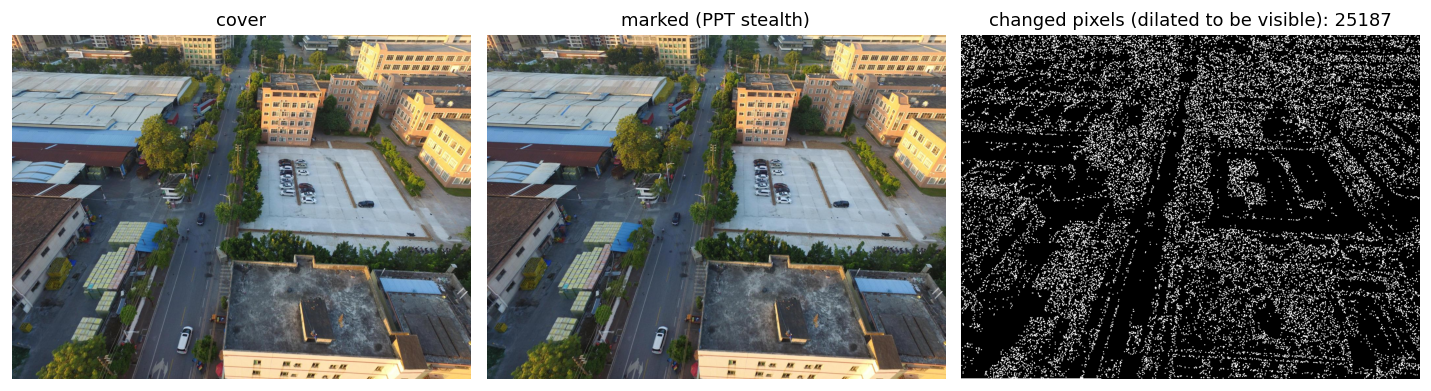

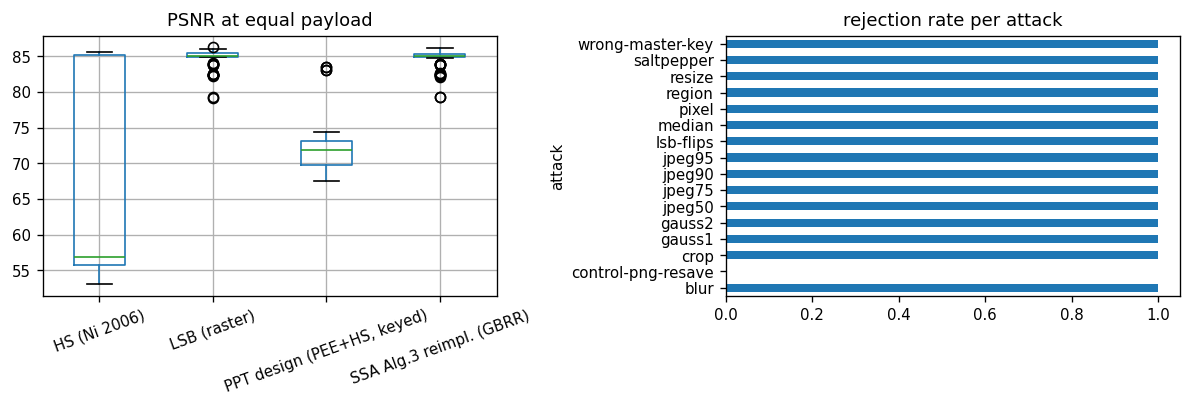

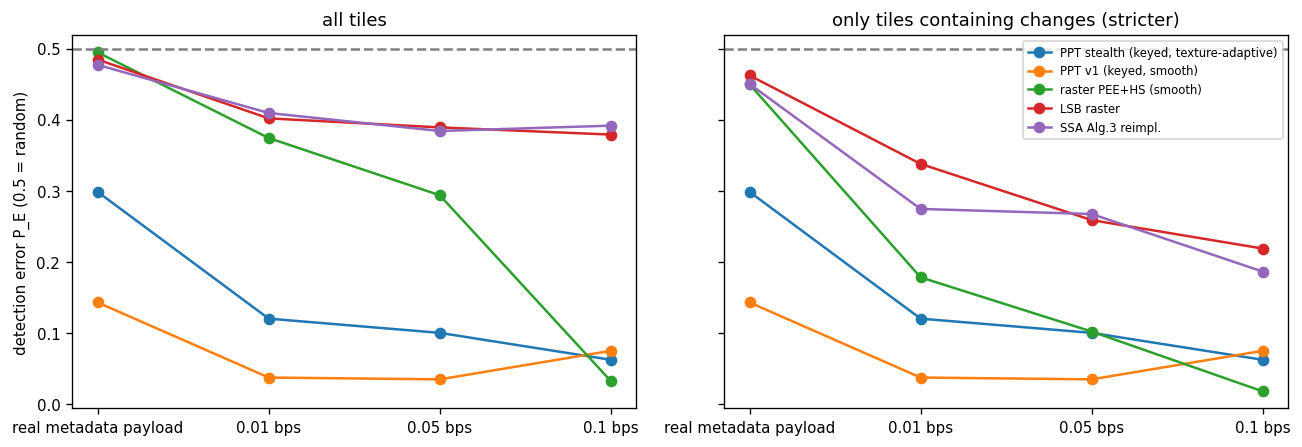

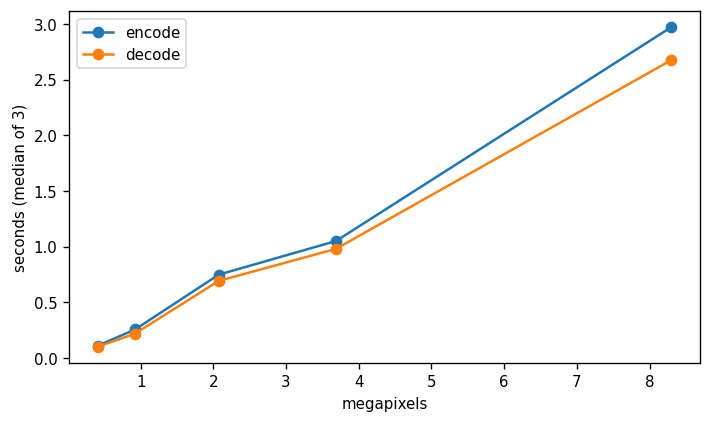

In [ ]:
plt.rcParams.update({"figure.dpi": 120, "font.size": 9})
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
item, cover, rec, enc, *_r = prepared[15]
ax[0].imshow(cover); ax[0].set_title("cover"); ax[0].axis("off")
ax[1].imshow(enc.marked); ax[1].set_title("marked (PPT stealth)"); ax[1].axis("off")
diff = np.abs(enc.marked.astype(int) - cover.astype(int)).max(axis=2)
ax[2].imshow(cv2.dilate((diff > 0).astype(np.uint8), np.ones((3, 3), np.uint8)), cmap="gray"); ax[2].set_title(f"changed pixels (dilated to be visible): {int((diff > 0).sum())}"); ax[2].axis("off")
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "figures", "example_cover_marked_diff.png")); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ok = base_df[np.isfinite(base_df["psnr"].astype(float))]
ok.boxplot(column="psnr", by="method", ax=ax[0], rot=20); ax[0].set_title("PSNR at equal payload"); ax[0].set_xlabel("")
att_plot = att_summary.set_index("attack")["reject_rate"]
att_plot.plot.barh(ax=ax[1]); ax[1].set_xlim(0, 1.05); ax[1].set_title("rejection rate per attack")
plt.suptitle(""); plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "figures", "baselines_and_attacks.png")); plt.show()

if len(steg_df):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for m, g in steg_df.groupby("method", sort=False):
        ax[0].plot(g["payload"], g["P_E"], marker="o", label=m)
        ax[1].plot(g["payload"], g["P_E_modified_tiles"], marker="o", label=m)
    for a, t in zip(ax, ["all tiles", "only tiles containing changes (stricter)"]):
        a.axhline(0.5, ls="--", c="gray"); a.set_title(t)
    ax[0].set_ylabel("detection error P_E (0.5 = random)"); ax[1].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "figures", "steganalysis_spam_fld.png")); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(scal_df["pixels"] / 1e6, scal_df["encode_s"], marker="o", label="encode")
ax.plot(scal_df["pixels"] / 1e6, scal_df["decode_s"], marker="o", label="decode")
ax.set_xlabel("megapixels"); ax.set_ylabel("seconds (median of 3)"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "figures", "scalability.png")); plt.show()

## Export
Everything produced by this run (tables, figures, an example marked PNG, environment info) is zipped for download. The experiment master key file is **excluded** from the archive.

In [ ]:
env = {"python": sys.version, "numpy": np.__version__, "opencv": cv2.__version__, "exiftool": HAVE_EXIFTOOL,
       "colab": IN_COLAB, "seed": GLOBAL_SEED, "n_runs": N_RUNS, "max_side": MAX_SIDE,
       "datasets": DATASET_STATUS, "timestamp_utc": datetime.now(timezone.utc).isoformat()}
with open(os.path.join(RUN_DIR, "environment.json"), "w") as f:
    json.dump(env, f, indent=2, default=str)
archive = shutil.make_archive("uavmeta_results", "zip", RUN_DIR)
with __import__("zipfile").ZipFile(archive) as z:
    names = [n for n in z.namelist() if "master_key" not in n]
tmp = archive.replace(".zip", "_clean.zip")
import zipfile
with zipfile.ZipFile(archive) as zin, zipfile.ZipFile(tmp, "w", zipfile.ZIP_DEFLATED) as zout:
    for n in names: zout.writestr(n, zin.read(n))
os.replace(tmp, archive)
print("Results archive:", archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)

Results archive: /content/uavmeta_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 19. Use it on your own image

**Protect:** upload any photo (drone, phone or camera; JPG/PNG/TIFF, optionally with a DJI `.SRT` telemetry file of the same name). Real EXIF/XMP/SRT fields are read; the form fields override them; missing fields are left out unless `FILL_MISSING_WITH_SYNTHETIC` is ticked. The cell embeds the encrypted record with the stealth embedder, self-checks the result and downloads `marked_<name>.png`.

**Verify:** upload a marked PNG to get ACCEPT + the metadata + the bit-exact original, or REJECT if anything changed.

To use only these two cells without the long experiment: run Sections 1–14 (up to and including the self-test), then jump here. Set a Colab secret `UAV_MASTER_KEY_HEX` so images protected today can still be verified in a later session.

In [ ]:
#@title Embed secure metadata into YOUR OWN image
# Upload one or more photos (JPG/PNG/TIFF). Optional: upload a DJI .SRT telemetry file with the same base name.
# Real EXIF/XMP/SRT fields are used first; the fields below override them; anything still missing is either
# synthesised (and listed under "syn" in the record) or left out, depending on FILL_MISSING_WITH_SYNTHETIC.
MY_IMAGE_PATHS = ""          #@param {type:"string"}
# ^ optional: comma-separated paths (e.g. on Google Drive). Leave empty to get an upload button.
KEEP_FULL_RESOLUTION = True  #@param {type:"boolean"}
FILL_MISSING_WITH_SYNTHETIC = False  #@param {type:"boolean"}
MISSION_ID = ""   #@param {type:"string"}
OPERATOR_ID = ""  #@param {type:"string"}
LATITUDE = ""     #@param {type:"string"}
LONGITUDE = ""    #@param {type:"string"}
ALTITUDE_M = ""   #@param {type:"string"}
BATTERY_PCT = ""  #@param {type:"string"}

MY_OUT_DIR = os.path.join(RUN_DIR, "my_images"); os.makedirs(MY_OUT_DIR, exist_ok=True)

def _my_inputs():
    if MY_IMAGE_PATHS.strip():
        paths = [p.strip() for p in MY_IMAGE_PATHS.split(",") if p.strip()]
        for p in paths: _maybe_mount_drive(p)
        return paths
    if not IN_COLAB:
        raise RuntimeError("Outside Colab, set MY_IMAGE_PATHS to one or more image paths.")
    from google.colab import files
    up_dir = os.path.join(MY_OUT_DIR, "uploads"); os.makedirs(up_dir, exist_ok=True)
    paths = []
    for name, data in files.upload().items():
        p = os.path.join(up_dir, os.path.basename(name))
        with open(p, "wb") as f: f.write(data)
        paths.append(p)
    return paths

def _manual_fields():
    out = {}
    for name, v in [("lat", LATITUDE), ("lon", LONGITUDE), ("alt", ALTITUDE_M), ("battery", BATTERY_PCT)]:
        if str(v).strip():
            out[name] = float(v)
    if MISSION_ID.strip(): out["mission"] = MISSION_ID.strip()
    if OPERATOR_ID.strip(): out["operator"] = OPERATOR_ID.strip()
    return out

def protect_my_image(path, srt_path=None, rng=None):
    rng = rng or np.random.default_rng()
    cover, scale = load_cover(path, max_side=0 if KEEP_FULL_RESOLUTION else MAX_SIDE)
    raw = extract_exif_xmp(path)
    if srt_path:
        entries = parse_srt(open(srt_path, errors="ignore").read())
        if entries:
            raw = {**raw, **entries[0]}
    canon = {**canonicalise(raw), **_manual_fields()}
    real = sorted(canon)
    if FILL_MISSING_WITH_SYNTHETIC:
        canon, syn = synthesise_missing(canon, rng)
    else:
        syn = []
    rec, prio = filter_and_serialise(canon, syn, cover_hash(cover))
    enc = encode_image(cover, rec, KEYS)
    dec = decode_image(enc.marked, K_MASTER)              # self-check before handing the file out
    out = os.path.join(MY_OUT_DIR, "marked_" + os.path.splitext(os.path.basename(path))[0] + ".png")
    save_png_stripped(enc.marked, out)
    mse = float(np.mean((cover.astype(np.float64) - enc.marked) ** 2))
    print(f"\n=== {os.path.basename(path)} -> {os.path.basename(out)}")
    print(f"size {cover.shape[1]}x{cover.shape[0]} (scale {scale:.3f}) | record {len(rec)} B | payload {len(enc.payload_bits)} bits"
          f" | PSNR {10 * math.log10(255 ** 2 / mse) if mse else float('inf'):.2f} dB | changed pixels"
          f" {int((np.abs(enc.marked.astype(int) - cover).max(2) > 0).sum())} | mode {enc.info.get('selection')}")
    print("self-check:", dec.verdict, "| image exact:", dec.restored is not None and np.array_equal(dec.restored, cover))
    print("real fields:", [f for f in real if f in cbor2.loads(rec)] or "none (no EXIF/XMP/SRT and nothing entered above)")
    print("synthetic fields:", syn or "none")
    print("embedded metadata:", json.dumps(record_to_json(cbor2.loads(rec)), default=str))
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
    ax[0].imshow(cover); ax[0].set_title("your image"); ax[0].axis("off")
    ax[1].imshow(enc.marked); ax[1].set_title("protected (marked PNG)"); ax[1].axis("off")
    diff = np.abs(enc.marked.astype(int) - cover.astype(int)).max(axis=2) > 0
    ax[2].imshow(cv2.dilate(diff.astype(np.uint8), np.ones((3, 3), np.uint8)), cmap="gray")
    ax[2].set_title(f"where pixels changed (x3 dilated): {int(diff.sum())}"); ax[2].axis("off")
    plt.tight_layout(); plt.show()
    return out

if KEY_SOURCE.startswith("generated"):
    print("NOTE: the master key was generated for this runtime only. Marked images can be decoded only with this\n"
          "      runtime's key (uavmeta_run/experiment_master_key.hex). To decode them in any later session, add a\n"
          "      Colab secret UAV_MASTER_KEY_HEX (64 hex chars; create one with: import os; os.urandom(32).hex()).")

_paths = _my_inputs()
_srts = {os.path.splitext(os.path.basename(p))[0].lower(): p for p in _paths if p.lower().endswith(".srt")}
MY_MARKED = []
for p in _paths:
    if p.lower().endswith(".srt"):
        continue
    try:
        MY_MARKED.append(protect_my_image(p, _srts.get(os.path.splitext(os.path.basename(p))[0].lower())))
    except Exception as e:
        print(f"{os.path.basename(p)}: could not protect ({type(e).__name__}: {e})")
if IN_COLAB and MY_MARKED and not MY_IMAGE_PATHS.strip():
    from google.colab import files
    for p in MY_MARKED: files.download(p)
print("\nKeep the marked files as PNG. Re-saving as JPG, editing, or sending through apps that recompress images"
      " will (correctly) make verification REJECT them.")


In [ ]:
#@title Verify a protected PNG and recover the metadata + original image
# Upload marked PNGs (from the cell above, or received from someone using the same master key),
# or list their paths. Needs the SAME master key that embedded them.
MARKED_PATHS = ""  #@param {type:"string"}
MY_OUT_DIR = os.path.join(RUN_DIR, "my_images"); os.makedirs(MY_OUT_DIR, exist_ok=True)

def _marked_inputs():
    if MARKED_PATHS.strip():
        paths = [p.strip() for p in MARKED_PATHS.split(",") if p.strip()]
        for p in paths: _maybe_mount_drive(p)
        return paths
    if not IN_COLAB:
        return list(globals().get("MY_MARKED", []))
    from google.colab import files
    up_dir = os.path.join(MY_OUT_DIR, "to_verify"); os.makedirs(up_dir, exist_ok=True)
    paths = []
    for name, data in files.upload().items():
        p = os.path.join(up_dir, os.path.basename(name))
        with open(p, "wb") as f: f.write(data)
        paths.append(p)
    return paths

def verify_marked(path):
    im = Image.open(path)
    if im.format != "PNG":
        print(f"\n=== {os.path.basename(path)}: REJECT (file is {im.format}, not the lossless PNG that was produced)")
        return None
    marked = np.asarray(im.convert("RGB"), dtype=np.uint8).copy()
    d = decode_image(marked, K_MASTER)
    print(f"\n=== {os.path.basename(path)}: {d.verdict}" + ("" if d.verdict == "ACCEPT" else f"  (failed at: {d.stage})"))
    if d.verdict != "ACCEPT":
        print("Metadata NOT released: the image was modified, re-encoded, or embedded with a different master key.")
        return None
    meta = record_to_json(d.record)
    print("metadata:", json.dumps({k: v for k, v in meta.items() if k != "h"}, default=str, indent=1))
    print("synthetic (not measured) fields:", d.record.get("syn") or "none")
    print("binding: SHA-256 of restored image matches the hash sealed inside the metadata")
    out = os.path.join(MY_OUT_DIR, "restored_" + os.path.splitext(os.path.basename(path))[0].replace("marked_", "") + ".png")
    save_png_stripped(d.restored, out)
    print("bit-exact original restored to:", out)
    return out

RESTORED = [r for r in (verify_marked(p) for p in _marked_inputs()) if r]
if IN_COLAB and RESTORED and not MARKED_PATHS.strip():
    from google.colab import files
    for p in RESTORED: files.download(p)
